# Сапёр

Реализация игры "Сапёр" на NumPy и PyTorch. Правила игры реализованы в этом ноутбуке. Результаты и порядок запуска — в [README](README.md)


In [18]:
from __future__ import annotations

import csv
import hashlib
import platform
import shutil
from datetime import datetime, timezone
import json
import os
from dataclasses import asdict, dataclass, replace
from math import comb
from pathlib import Path
from tempfile import TemporaryDirectory

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F


def choose_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


DEVICE = choose_device()

## Собственная среда сапёра

После `reset()` все клетки закрыты, а мины ещё не размещены. Первый `step(action)` размещает их равномерно среди остальных клеток. Если число в открытой клетке больше нуля, открывается только она. Если число равно нулю, обходятся все связанные через восемь направлений нули и открываются числа на границе этой области. Попадание на мину или открытие всех безопасных клеток завершает партию.

`visible` содержит `-1` для закрытой клетки, `0…8` для открытого числа и `-2` для взорванной мины. Скрытые `mines` доступны генератору меток, но не функции кодирования входа.

In [19]:
UNKNOWN = -1
EXPLODED_MINE = -2


class MinesweeperGame:
    def __init__(self, rows=6, cols=6, n_mines=4, rng=None,
                 fixed_layout=None, forbidden_layouts=()):
        if not 0 < n_mines < rows * cols:
            raise ValueError("Число мин должно быть от 1 до числа клеток минус 1")
        self.rows, self.cols, self.n_mines = rows, cols, n_mines
        self.rng = rng if rng is not None else np.random.default_rng()
        self.fixed_layout = None if fixed_layout is None else tuple(sorted(fixed_layout))
        self.forbidden_layouts = frozenset(forbidden_layouts)
        self.reset()

    def reset(self):
        self.visible = np.full((self.rows, self.cols), UNKNOWN, dtype=np.int8)
        self.mines = None
        self.clues = None
        self.done = False
        self.won = False
        return self.visible.copy()

    def _neighbors(self, row, col):
        for nr in range(max(0, row - 1), min(self.rows, row + 2)):
            for nc in range(max(0, col - 1), min(self.cols, col + 2)):
                if (nr, nc) != (row, col):
                    yield nr, nc

    def _place_mines(self, first_action):
        if self.fixed_layout is not None:
            layout = self.fixed_layout
            if len(layout) != self.n_mines or len(set(layout)) != self.n_mines:
                raise ValueError("Некорректная фиксированная карта мин")
            if any(i < 0 or i >= self.rows * self.cols for i in layout):
                raise ValueError("Индекс мины вне поля")
            if first_action in layout:
                raise ValueError("Первый ход должен быть безопасным")
        else:
            allowed = np.array(
                [i for i in range(self.rows * self.cols) if i != first_action],
                dtype=np.int64,
            )
            while True:
                layout = tuple(sorted(int(i) for i in self.rng.choice(
                    allowed, size=self.n_mines, replace=False
                )))
                if layout not in self.forbidden_layouts:
                    break

        self.mines = np.zeros((self.rows, self.cols), dtype=bool)
        self.mines.flat[list(layout)] = True
        self.clues = np.zeros((self.rows, self.cols), dtype=np.int8)
        for mine_index in layout:
            row, col = divmod(mine_index, self.cols)
            for nr, nc in self._neighbors(row, col):
                if not self.mines[nr, nc]:
                    self.clues[nr, nc] += 1

    def _reveal(self, row, col):
        stack = [(row, col)]
        opened = 0
        while stack:
            row, col = stack.pop()
            if self.visible[row, col] != UNKNOWN:
                continue
            assert not self.mines[row, col]
            self.visible[row, col] = self.clues[row, col]
            opened += 1
            if self.clues[row, col] == 0:
                for nr, nc in self._neighbors(row, col):
                    if self.visible[nr, nc] == UNKNOWN:
                        stack.append((nr, nc))
        return opened

    def step(self, action):
        action = int(action)
        if self.done:
            raise RuntimeError("Партия завершена; вызови reset()")
        if not 0 <= action < self.rows * self.cols:
            raise ValueError("Индекс клетки вне поля")
        row, col = divmod(action, self.cols)
        if self.visible[row, col] != UNKNOWN:
            raise ValueError("Нельзя повторно открыть клетку")
        if self.mines is None:
            self._place_mines(action)

        if self.mines[row, col]:
            self.visible[row, col] = EXPLODED_MINE
            self.done = True
            opened = 1
        else:
            opened = self._reveal(row, col)
            self.won = bool(np.all(self.visible[~self.mines] >= 0))
            self.done = self.won
        return self.visible.copy(), self.done, {
            "won": self.won,
            "hit_mine": bool(self.mines[row, col]),
            "opened": opened,
        }


def board_text(visible):
    symbols = {UNKNOWN: "·", EXPLODED_MINE: "*"}
    return "\n".join(" ".join(symbols.get(int(x), str(int(x))) for x in row)
                     for row in visible)


### Проверка правил открытия

Проверяем полную видимую доску после раскрытия нулевой области, одиночное открытие числа, запрет повторного клика, поражение и победу. Фиксированные раскладки позволяют сверить ожидаемые состояния вручную.


In [20]:
_demo = MinesweeperGame(fixed_layout=(21, 27, 28, 35))
assert _demo.mines is None
assert np.all(_demo.visible == UNKNOWN)
_, _done, _info = _demo.step(0)
_expected = np.array([
    [0, 0, 0, 0, 0, 0],
    [0, 0, 0, 0, 0, 0],
    [0, 0, 1, 1, 1, 0],
    [0, 0, 2, -1, 3, 1],
    [0, 0, 2, -1, -1, -1],
    [0, 0, 1, -1, -1, -1],
], dtype=np.int8)
np.testing.assert_array_equal(_demo.visible, _expected)
assert _info['opened'] == 29 and not _done
assert not _info['hit_mine']
try:
    _demo.step(0)
except ValueError:
    pass
else:
    raise AssertionError('Повторный клик должен быть запрещён')

_number_game = MinesweeperGame(fixed_layout=(1, 10, 20, 35))
_, _, _info = _number_game.step(0)
assert _info['opened'] == 1 and _number_game.visible.flat[0] == 1
_, _done, _info = _number_game.step(1)
assert _done and _info['hit_mine'] and not _info['won']
_win_game = MinesweeperGame(rows=2, cols=2, n_mines=1, fixed_layout=(3,))
for _action in (0, 1, 2):
    _, _done, _info = _win_game.step(_action)
assert _done and _info['won']
print(board_text(_demo.visible))
print('Проверки правил игры прошли; нулевая область открыла 29 клеток.')


0 0 0 0 0 0
0 0 0 0 0 0
0 0 1 1 1 0
0 0 2 · 3 1
0 0 2 · · ·
0 0 1 · · ·
Проверки правил игры прошли; нулевая область открыла 29 клеток.


## Вход, метка, сеть и функция ошибки

Вход имеет форму `[2, 6, 6]`:

- Канал 0: открытое число, делённое на 8. У закрытой клетки здесь 0.
- Канал 1: `1` у закрытой клетки и `0` у открытой. Он позволяет отличить закрытую клетку от открытого нуля.

Метка — плоский вектор из 36 значений: `1` для мины, `0` для безопасной клетки. Архитектура: три свёртки `3×3` с 64 каналами, затем `2304 → 256 → 256 → 36`. Она выдаёт логиты, поэтому для обучения применяется `binary_cross_entropy_with_logits`. В ошибку входят только закрытые клетки. Если в пакете их разное количество, усредняем по общему числу закрытых клеток пакета.
Для поля 6×6 модель содержит 740 196 параметров. Dropout отсутствует


In [21]:
def encode_visible(visible):
    numbers = np.where(visible >= 0, visible, 0).astype(np.float32) / 8.0
    hidden = (visible == UNKNOWN).astype(np.float32)
    return np.stack((numbers, hidden), axis=0)


class Network(nn.Module):
    def __init__(self, rows=6, cols=6):
        super().__init__()
        self.core = nn.Sequential(
            nn.Conv2d(2, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * rows * cols, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, rows * cols),
        )

    def forward(self, x):
        return self.core(x)


def masked_mine_loss(logits, targets, encoded_boards):
    hidden = encoded_boards[:, 1].flatten(start_dim=1)
    per_cell = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    return (per_cell * hidden).sum() / hidden.sum().clamp_min(1)


@torch.no_grad()
def choose_action(model, visible, device):
    encoded = torch.from_numpy(encode_visible(visible)).unsqueeze(0).to(device)
    logits = model(encoded).squeeze(0).cpu().numpy().copy()
    logits[visible.reshape(-1) != UNKNOWN] = np.inf
    if not np.isfinite(logits).any():
        raise RuntimeError("Закрытых клеток не осталось")
    return int(np.argmin(logits))


# Быстрая проверка форм и обратного прохода без обучения всей модели.
_probe = Network().to(DEVICE)
_probe_x = torch.from_numpy(encode_visible(_demo.visible)).unsqueeze(0).to(DEVICE)
_probe_y = torch.from_numpy(_demo.mines.reshape(1, -1).astype(np.float32)).to(DEVICE)
_probe_logits = _probe(_probe_x)
assert _probe_x.shape == (1, 2, 6, 6)
assert _probe_logits.shape == (1, 36)
_probe_loss = masked_mine_loss(_probe_logits, _probe_y, _probe_x)
assert torch.isfinite(_probe_loss)
_probe_loss.backward()
print("Размер входа:", tuple(_probe_x.shape), "выхода:", tuple(_probe_logits.shape))

Размер входа: (1, 2, 6, 6) выхода: (1, 36)



На поле 6×6 с четырьмя минами и безопасной клеткой `0` существует `C(35, 4) = 52 360` расстановок. Фиксированный генератор выделяет 256 уникальных раскладок для валидации и 2000 для теста. Для обучения остаётся 50 104 возможных расстановки. Их состояния могут повторяться; два миллиона кликов не означают два миллиона уникальных досок.

Разделение проводится по полной карте мин, а не по отдельным состояниям партии. Обучающий генератор исключает validation/test-раскладки. Это не исключает совпадения частичных наблюдений или симметричных досок между частями. Для воспроизведения существующего эксперимента алгоритм разделения и seed сохраняются.


In [22]:
@dataclass
class Config:
    rows: int = 6
    cols: int = 6
    n_mines: int = 4
    seed: int = 42
    first_action: int = 0
    collect_size: int = 320
    epochs_per_collect: int = 10
    batch_size: int = 32
    learning_rate: float = 1e-5
    max_env_steps: int = 500_000
    validation_games: int = 256
    test_games: int = 2_000
    eval_every_rounds: int = 25
    checkpoint_every_rounds: int = 25
    print_every_rounds: int = 10


    def __post_init__(self):
        positive = ('rows', 'cols', 'collect_size', 'epochs_per_collect',
                    'batch_size', 'validation_games', 'test_games',
                    'eval_every_rounds', 'checkpoint_every_rounds',
                    'print_every_rounds')
        if any(getattr(self, key) <= 0 for key in positive):
            raise ValueError('Размеры, интервалы и числа партий должны быть положительными')
        if not 0 < self.n_mines < self.rows * self.cols:
            raise ValueError('Некорректное число мин')
        if not 0 <= self.first_action < self.rows * self.cols:
            raise ValueError('Первый ход вне поля')
        if not np.isfinite(self.learning_rate) or self.learning_rate <= 0:
            raise ValueError('learning_rate должен быть положительным и конечным')
        if self.max_env_steps < 0:
            raise ValueError('max_env_steps должен быть неотрицательным')
        possible = comb(self.rows * self.cols - 1, self.n_mines)
        if self.validation_games + self.test_games >= possible:
            raise ValueError('После выделения validation/test должна остаться train-раскладка')


def make_holdout_layouts(cfg):
    rng = np.random.default_rng(cfg.seed + 10_000)
    allowed = np.array([i for i in range(cfg.rows * cfg.cols)
                        if i != cfg.first_action], dtype=np.int64)
    count = cfg.validation_games + cfg.test_games
    layouts = set()
    while len(layouts) < count:
        layout = tuple(sorted(int(i) for i in rng.choice(
            allowed, size=cfg.n_mines, replace=False
        )))
        layouts.add(layout)
    ordered = sorted(layouts)
    rng.shuffle(ordered)
    return (ordered[:cfg.validation_games],
            ordered[cfg.validation_games:])


CFG = Config()
_val_layouts, _test_layouts = make_holdout_layouts(CFG)
assert set(_val_layouts).isdisjoint(_test_layouts)
print("Проверочных раскладок:", len(_val_layouts),
      "тестовых:", len(_test_layouts))


Проверочных раскладок: 256 тестовых: 2000


## Проверка качества полными партиями

При конфигурации эксперимента первая клетка `0`, затем модель выбирает минимальный логит среди закрытых клеток. Победа означает, что открыты все безопасные клетки. Здесь нет наград: метрика качества — доля выигранных партий. Функция не меняет веса и не использует метки при выборе действий.


In [23]:
@torch.no_grad()
def evaluate_policy(model, layouts, cfg, device):
    was_training = model.training
    model.eval()
    wins = 0
    moves_total = 0
    for layout in layouts:
        game = MinesweeperGame(cfg.rows, cfg.cols, cfg.n_mines,
                               fixed_layout=layout)
        _, done, info = game.step(cfg.first_action)
        moves = 1
        while not done:
            action = choose_action(model, game.visible, device)
            _, done, info = game.step(action)
            moves += 1
        wins += int(info["won"])
        moves_total += moves
    model.train(was_training)
    return {"win_rate": wins / len(layouts),
            "mean_moves": moves_total / len(layouts),
            "games": len(layouts)}

## Обучение, CSV-логи и checkpoints

После каждого безопасного нетерминального хода сохраняется один пример. При 320 примерах выполняются 10 локальных эпох с перемешиванием и пакетами по 32, затем буфер очищается: 100 обновлений Adam на одну порцию. При достижении лимита кликов текущая партия доигрывается, поэтому счётчик может немного превысить лимит.

`latest.pt` сохраняется на границе партий: веса, Adam, счётчики, неполный буфер, NumPy RNG и CPU Torch RNG (перемешивание использует CPU). В текущей сети нет стохастических слоёв; побитовая воспроизводимость между разными устройствами не гарантируется. `best.pt` — отдельные веса, выбранные по максимуму доли побед на валидации. Для оценки в этом проекте выбран `latest.pt`.

`episodes.csv` и `updates.csv` содержат историю. Новые checkpoints также фиксируют размеры логов. При восстановлении строки после checkpoint удаляются из рабочих CSV с сохранением исходных файлов в `recovery/`. Для старых checkpoints используется сверка счётчиков. `config.json` обновляется при продолжении. Checkpoints записываются через временный файл и атомарную замену; старые версии `latest.pt` автоматически не архивируются.


In [24]:
def append_csv(path, fields, row):
    path = Path(path)
    write_header = not path.exists() or path.stat().st_size == 0
    with path.open("a", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=fields)
        if write_header:
            writer.writeheader()
        writer.writerow(row)


def write_json_atomic(path, data):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(data, ensure_ascii=False, indent=2) + '\n',
                         encoding='utf-8')
    os.replace(temporary, path)


class Trainer:
    def __init__(self, cfg, run_dir, device=DEVICE, resume=False):
        self.cfg = cfg
        self.run_dir = Path(run_dir)
        self.run_dir.mkdir(parents=True, exist_ok=True)
        self.device = torch.device(device)
        self.validation_layouts, self.test_layouts = make_holdout_layouts(cfg)
        self.forbidden_layouts = set(self.validation_layouts + self.test_layouts)
        self.rng = np.random.default_rng(cfg.seed)
        torch.manual_seed(cfg.seed)
        self.model = Network(cfg.rows, cfg.cols).to(self.device)
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=cfg.learning_rate)
        self.env_steps = 0
        self.episodes = 0
        self.update_rounds = 0
        self.optimizer_steps = 0
        self.best_val_win_rate = -1.0
        self.buffer_x = []
        self.buffer_y = []
        self.save_pending = False
        self.latest_path = self.run_dir / "latest.pt"
        self.best_path = self.run_dir / "best.pt"
        self.episodes_path = self.run_dir / "episodes.csv"
        self.updates_path = self.run_dir / "updates.csv"

        if resume:
            self.load_latest()
        elif any(path.exists() for path in (self.latest_path, self.best_path,
                                             self.episodes_path, self.updates_path)):
            raise FileExistsError(
                f"В {self.run_dir} уже есть данные обучения: установи resume=True "
                "или выбери другой run_dir"
            )
        write_json_atomic(self.run_dir / "config.json", asdict(cfg))

    def add_sample(self, game):
        self.buffer_x.append(encode_visible(game.visible))
        self.buffer_y.append(game.mines.reshape(-1).astype(np.float32).copy())
        if len(self.buffer_x) >= self.cfg.collect_size:
            self.train_buffer()

    def train_buffer(self):
        count = len(self.buffer_x)
        assert count == self.cfg.collect_size
        x = torch.from_numpy(np.stack(self.buffer_x)).to(self.device)
        y = torch.from_numpy(np.stack(self.buffer_y)).to(self.device)
        self.model.train()
        losses = []
        for _ in range(self.cfg.epochs_per_collect):
            order = torch.randperm(count)
            for start in range(0, count, self.cfg.batch_size):
                indices = order[start:start + self.cfg.batch_size].to(self.device)
                batch_x, batch_y = x[indices], y[indices]
                self.optimizer.zero_grad(set_to_none=True)
                logits = self.model(batch_x)
                loss = masked_mine_loss(logits, batch_y, batch_x)
                loss.backward()
                self.optimizer.step()
                losses.append(float(loss.item()))
                self.optimizer_steps += 1

        self.buffer_x.clear()
        self.buffer_y.clear()
        self.update_rounds += 1
        mean_loss = float(np.mean(losses))
        metrics = {
            "env_steps": self.env_steps,
            "episodes": self.episodes,
            "update_rounds": self.update_rounds,
            "optimizer_steps": self.optimizer_steps,
            "train_loss": mean_loss,
            "val_win_rate": "",
            "val_mean_moves": "",
        }

        if self.update_rounds % self.cfg.eval_every_rounds == 0:
            val = evaluate_policy(self.model, self.validation_layouts,
                                  self.cfg, self.device)
            metrics["val_win_rate"] = val["win_rate"]
            metrics["val_mean_moves"] = val["mean_moves"]
            if val["win_rate"] > self.best_val_win_rate:
                self.best_val_win_rate = val["win_rate"]
                self.save_best()
            print(f"Шаги={self.env_steps:,}, партии={self.episodes:,}, "
                  f"loss={mean_loss:.4f}, val win={val['win_rate']:.1%}")
        elif self.update_rounds % self.cfg.print_every_rounds == 0:
            print(f"Шаги={self.env_steps:,}, партии={self.episodes:,}, "
                  f"loss={mean_loss:.4f}")

        append_csv(self.updates_path, list(metrics), metrics)
        if self.update_rounds % self.cfg.checkpoint_every_rounds == 0:
            self.save_pending = True

    def save_best(self):
        payload = {
            "model": self.model.state_dict(),
            "config": asdict(self.cfg),
            "env_steps": self.env_steps,
            "val_win_rate": self.best_val_win_rate,
        }
        temporary = self.best_path.with_suffix(".tmp")
        torch.save(payload, temporary)
        os.replace(temporary, self.best_path)

    def save_latest(self):
        empty_x = np.empty((0, 2, self.cfg.rows, self.cfg.cols), dtype=np.float32)
        empty_y = np.empty((0, self.cfg.rows * self.cfg.cols), dtype=np.float32)
        payload = {
            "model": self.model.state_dict(),
            "optimizer": self.optimizer.state_dict(),
            "config": asdict(self.cfg),
            "env_steps": self.env_steps,
            "episodes": self.episodes,
            "update_rounds": self.update_rounds,
            "optimizer_steps": self.optimizer_steps,
            "best_val_win_rate": self.best_val_win_rate,
            "buffer_x": torch.from_numpy(np.stack(self.buffer_x)
                                         if self.buffer_x else empty_x),
            "buffer_y": torch.from_numpy(np.stack(self.buffer_y)
                                         if self.buffer_y else empty_y),
            "numpy_rng_json": json.dumps(self.rng.bit_generator.state),
            "torch_rng": torch.get_rng_state(),
            "log_sizes": {
                path.name: path.stat().st_size if path.exists() else 0
                for path in (self.episodes_path, self.updates_path)
            },
        }
        temporary = self.latest_path.with_suffix(".tmp")
        torch.save(payload, temporary)
        os.replace(temporary, self.latest_path)
        self.save_pending = False

    def load_latest(self):
        checkpoint = torch.load(self.latest_path, map_location=self.device,
                                weights_only=True)
        if self.cfg.max_env_steps < checkpoint['env_steps']:
            raise ValueError('max_env_steps меньше текущего шага. Это не откатывает веса; '
                             'для оценки используйте отдельную ячейку загрузки.')
        old = checkpoint["config"]
        immutable = ("rows", "cols", "n_mines", "seed", "first_action",
                     "collect_size", "epochs_per_collect", "batch_size",
                     "learning_rate", "validation_games", "test_games")
        changed = [key for key in immutable if old[key] != getattr(self.cfg, key)]
        if changed:
            raise ValueError(f"При продолжении изменились параметры: {changed}")
        self.model.load_state_dict(checkpoint["model"])
        self.optimizer.load_state_dict(checkpoint["optimizer"])
        self.env_steps = int(checkpoint["env_steps"])
        self.episodes = int(checkpoint["episodes"])
        self.update_rounds = int(checkpoint["update_rounds"])
        self.optimizer_steps = int(checkpoint["optimizer_steps"])
        self.best_val_win_rate = float(checkpoint["best_val_win_rate"])
        self.buffer_x = [x.copy() for x in checkpoint["buffer_x"].cpu().numpy()]
        self.buffer_y = [y.copy() for y in checkpoint["buffer_y"].cpu().numpy()]
        self.rng.bit_generator.state = json.loads(checkpoint["numpy_rng_json"])
        torch.set_rng_state(checkpoint["torch_rng"].cpu())
        self.reconcile_logs(checkpoint)
        print(f"Продолжение: {self.env_steps:,} ходов, "
              f"{self.episodes:,} партий, {len(self.buffer_x)} примеров в буфере")

    def reconcile_logs(self, checkpoint):
        # Сначала проверяем оба файла, затем сохраняем резервные копии и правим хвосты.
        replacements = []
        for path in (self.episodes_path, self.updates_path):
            data = path.read_bytes() if path.exists() else b''
            if 'log_sizes' in checkpoint:
                saved_size = checkpoint['log_sizes'][path.name]
                if len(data) < saved_size:
                    raise ValueError(f'{path}: лог короче сохранённого checkpoint')
                kept = data[:saved_size]
            else:
                # Совместимость с уже обученной моделью: в старом формате нет offsets.
                lines = data.splitlines(keepends=True)
                kept_lines = lines[:1]
                header = next(csv.reader([lines[0].decode('utf-8')])) if lines else []
                for line in lines[1:]:
                    try:
                        values = next(csv.reader([line.decode('utf-8')]))
                        row = dict(zip(header, values))
                        counter_limits = {
                            'env_steps': self.env_steps, 'episode': self.episodes,
                            'episodes': self.episodes, 'update_rounds': self.update_rounds,
                            'optimizer_steps': self.optimizer_steps,
                        }
                        valid = (len(values) == len(header)
                                 and all(int(row[key]) <= limit
                                         for key, limit in counter_limits.items()
                                         if key in row))
                    except (ValueError, UnicodeDecodeError, csv.Error):
                        valid = False
                    if valid:
                        kept_lines.append(line)
                kept = b''.join(kept_lines)
            if data != kept:
                replacements.append((path, kept))
        if replacements:
            stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
            recovery = self.run_dir / 'recovery' / stamp
            recovery.mkdir(parents=True)
            for path, kept in replacements:
                shutil.copy2(path, recovery / path.name)
                temporary = path.with_suffix('.tmp')
                temporary.write_bytes(kept)
                os.replace(temporary, path)
            print(f'Логи восстановлены до checkpoint; прежние файлы: {recovery}')

    def train(self):
        if self.env_steps >= self.cfg.max_env_steps:
            print(f'Лимит уже достигнут: {self.env_steps:,} кликов. '
                  'Для продолжения увеличьте max_env_steps.')
            return
        while self.env_steps < self.cfg.max_env_steps:
            game = MinesweeperGame(
                self.cfg.rows, self.cfg.cols, self.cfg.n_mines,
                rng=self.rng, forbidden_layouts=self.forbidden_layouts,
            )
            _, done, info = game.step(self.cfg.first_action)
            self.env_steps += 1
            moves = 1
            if not done:
                self.add_sample(game)

            while not done:
                action = choose_action(self.model, game.visible, self.device)
                _, done, info = game.step(action)
                self.env_steps += 1
                moves += 1
                if not done:
                    self.add_sample(game)

            self.episodes += 1
            append_csv(self.episodes_path,
                       ["env_steps", "episode", "won", "moves"],
                       {"env_steps": self.env_steps,
                        "episode": self.episodes,
                        "won": int(info["won"]),
                        "moves": moves})
            if self.save_pending:
                self.save_latest()

        # Проверим и короткий запуск, который закончился до очередной плановой валидации.
        if self.update_rounds and self.update_rounds % self.cfg.eval_every_rounds != 0:
            val = evaluate_policy(self.model, self.validation_layouts,
                                  self.cfg, self.device)
            if val["win_rate"] > self.best_val_win_rate:
                self.best_val_win_rate = val["win_rate"]
                self.save_best()
            append_csv(self.updates_path,
                       ["env_steps", "episodes", "update_rounds", "optimizer_steps",
                        "train_loss", "val_win_rate", "val_mean_moves"],
                       {"env_steps": self.env_steps,
                        "episodes": self.episodes,
                        "update_rounds": self.update_rounds,
                        "optimizer_steps": self.optimizer_steps,
                        "train_loss": "",
                        "val_win_rate": val["win_rate"],
                        "val_mean_moves": val["mean_moves"]})
            print(f"Итоговая валидация: {val['win_rate']:.1%} побед")
        self.save_latest()
        print(f"Готово: {self.env_steps:,} ходов, {self.episodes:,} партий; "
              f"последний checkpoint: {self.latest_path}")


### Проверка сохранения и продолжения

Короткий запуск на CPU проверяет значения весов и состояния Adam, содержимое буфера, оба RNG и счётчики. Затем две копии одного состояния обучаются до следующего лимита: одна в том же объекте, другая после загрузки с диска. Их итоговые checkpoints должны совпасть. Также имитируется хвост CSV после сбоя и проверяется его восстановление. Рабочая папка эксперимента не используется.


In [25]:
def assert_nested_equal(left, right):
    if isinstance(left, torch.Tensor):
        assert torch.equal(left.cpu(), right.cpu())
    elif isinstance(left, dict):
        assert left.keys() == right.keys()
        for key in left:
            assert_nested_equal(left[key], right[key])
    elif isinstance(left, (list, tuple)):
        assert len(left) == len(right)
        for a, b in zip(left, right):
            assert_nested_equal(a, b)
    else:
        assert left == right


_previous_threads = torch.get_num_threads()
torch.set_num_threads(1)
try:
    with TemporaryDirectory(prefix='minesweeper-smoke-') as temporary_dir:
        smoke_cfg = Config(
            collect_size=8, epochs_per_collect=1, batch_size=4,
            max_env_steps=30, validation_games=4, test_games=4,
            eval_every_rounds=1, checkpoint_every_rounds=1,
            print_every_rounds=1,
        )
        run_a = Path(temporary_dir) / 'uninterrupted'
        run_b = Path(temporary_dir) / 'restored'
        smoke = Trainer(smoke_cfg, run_a, device='cpu')
        smoke.train()
        assert smoke.env_steps >= smoke_cfg.max_env_steps and smoke.update_rounds > 0
        before = torch.load(smoke.latest_path, map_location='cpu', weights_only=True)
        shutil.copytree(run_a, run_b)
        # Имитация записей, которые успели попасть в CSV после сохранения модели.
        for name in ('episodes.csv', 'updates.csv'):
            with (run_b / name).open('ab') as file:
                file.write(b'incomplete,row,after,checkpoint')
        restored = Trainer(smoke_cfg, run_b, device='cpu', resume=True)
        restored.save_latest()
        restored_state = torch.load(restored.latest_path, map_location='cpu', weights_only=True)
        assert_nested_equal(before, restored_state)
        for name in ('episodes.csv', 'updates.csv'):
            assert (run_a / name).read_bytes() == (run_b / name).read_bytes()
        assert len(list((run_b / 'recovery').glob('*/*.csv'))) == 2

        next_cfg = replace(smoke_cfg, max_env_steps=smoke.env_steps + 30)
        smoke.cfg = next_cfg
        smoke.train()
        resumed = Trainer(next_cfg, run_b, device='cpu', resume=True)
        resumed.train()
        after_a = torch.load(smoke.latest_path, map_location='cpu', weights_only=True)
        after_b = torch.load(resumed.latest_path, map_location='cpu', weights_only=True)
        assert_nested_equal(after_a, after_b)
        assert json.loads((run_b / 'config.json').read_text()) == asdict(next_cfg)
        print('Веса, Adam, буфер, RNG, восстановление логов и продолжение совпали.')
finally:
    torch.set_num_threads(_previous_threads)


Шаги=11, партии=3, loss=0.6981, val win=25.0%
Шаги=21, партии=5, loss=0.6956, val win=25.0%
Готово: 30 ходов, 8 партий; последний checkpoint: /var/folders/c1/_fwt7mbd5bz45__g4w2s4sd80000gn/T/minesweeper-smoke-4gtjvfjo/uninterrupted/latest.pt
Логи восстановлены до checkpoint; прежние файлы: /var/folders/c1/_fwt7mbd5bz45__g4w2s4sd80000gn/T/minesweeper-smoke-4gtjvfjo/restored/recovery/20261002T064448933422Z
Продолжение: 30 ходов, 8 партий, 6 примеров в буфере
Шаги=33, партии=9, loss=0.6968, val win=25.0%
Шаги=43, партии=11, loss=0.6974, val win=25.0%
Шаги=53, партии=13, loss=0.6975, val win=25.0%
Готово: 62 ходов, 15 партий; последний checkpoint: /var/folders/c1/_fwt7mbd5bz45__g4w2s4sd80000gn/T/minesweeper-smoke-4gtjvfjo/uninterrupted/latest.pt
Продолжение: 30 ходов, 8 партий, 6 примеров в буфере
Шаги=33, партии=9, loss=0.6968, val win=25.0%
Шаги=43, партии=11, loss=0.6974, val win=25.0%
Шаги=53, партии=13, loss=0.6975, val win=25.0%
Готово: 62 ходов, 15 партий; последний checkpoint: /var

## Запуск обучения и выбор весов для оценки

Для нового эксперимента задайте пустую папку `RUN_DIR`, `RESUME = False`, `RUN_LONG_TRAINING = True` и, например, `Config(max_env_steps=10_000)`. Папка создаётся автоматически; относительный путь отсчитывается от рабочей директории ядра. Для продолжения укажите ту же папку, `RESUME = True` и увеличьте общий лимит кликов. Смысловые параметры обучения менять при продолжении нельзя.

По умолчанию обучение выключено, а для оценки выбран `latest.pt` из завершённого запуска на 2 млн кликов. `EVAL_CHECKPOINT` — единственное место выбора весов для сравнения и разбора ошибок. Если локального checkpoint нет, используется опубликованный `checkpoints/latest.pt` после 2 млн кликов. Его также можно явно указать для воспроизведения результатов после нового обучения. Конфигурация оценки читается из самого checkpoint.


In [31]:
RUN_LONG_TRAINING = False
RESUME = True
RUN_DIR = Path('runs/minesweeper_two_channel')
TRAIN_CFG = Config(max_env_steps=4000000)
EVAL_CHECKPOINT = RUN_DIR / 'latest.pt'
if not EVAL_CHECKPOINT.exists():
    EVAL_CHECKPOINT = Path('checkpoints/latest.pt')

print('Папка запуска:', RUN_DIR.resolve())
if RUN_LONG_TRAINING:
    trainer = Trainer(TRAIN_CFG, RUN_DIR, device=DEVICE, resume=RESUME)
    trainer.train()
else:
    print('Долгое обучение выключено. Далее — оценка сохранённых весов.')


Папка запуска: /Users/a1234/Documents/ML/Minesweeper/runs/minesweeper_two_channel
Долгое обучение выключено. Далее — оценка сохранённых весов.


## История и загрузка выбранной модели

История берётся из `updates.csv`. Здесь модель загружается один раз; все сравнения ниже используют этот объект и конфигурацию из checkpoint. Вместе с результатами сохраняются SHA-256 файла, номер шага, версия библиотек и конкретные тестовые раскладки.

Статус теста: эти 2000 раскладок исключены из обучения, но их результаты уже просматривались при сравнении `best.pt` и `latest.pt`. Поэтому текущая таблица — повторная оценка на отложенных раскладках, а не независимый финальный тест после выбора модели. Для следующего эксперимента следует заранее зафиксировать правило выбора checkpoint и новый протокол проверки.


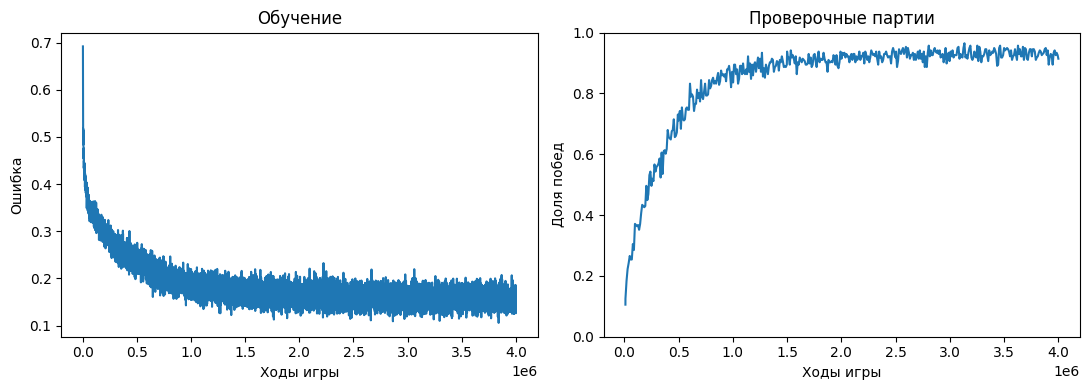

Checkpoint: runs/minesweeper_two_channel/latest.pt; кликов: 4,000,005
SHA-256: aa56ab00fe38062cfe21e8bc4be712477d1af7a79360e735bdc7becd1238036d
Параметров: 740196


In [32]:
if (RUN_DIR / "updates.csv").exists():
    import matplotlib.pyplot as plt

    with (RUN_DIR / "updates.csv").open(encoding="utf-8") as file:
        history = list(csv.DictReader(file))
    train_rows = [row for row in history if row["train_loss"] != ""]
    steps = [int(row["env_steps"]) for row in train_rows]
    losses = [float(row["train_loss"]) for row in train_rows]
    val_rows = [row for row in history if row["val_win_rate"] != ""]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(steps, losses)
    axes[0].set(xlabel="Ходы игры", ylabel="Ошибка", title="Обучение")
    if val_rows:
        axes[1].plot([int(row["env_steps"]) for row in val_rows],
                     [float(row["val_win_rate"]) for row in val_rows])
    axes[1].set(xlabel="Ходы игры", ylabel="Доля побед", ylim=(0, 1),
                title="Проверочные партии")
    fig.tight_layout()
    plt.show()
else:
    print("Истории обучения пока нет")



def load_evaluation_model(path, device):
    path = Path(path)
    checkpoint = torch.load(path, map_location='cpu', weights_only=True)
    cfg = Config(**checkpoint['config'])
    model = Network(cfg.rows, cfg.cols).to(device)
    model.load_state_dict(checkpoint['model'])
    model.eval()
    metadata = {
        'checkpoint': str(path),
        'checkpoint_sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
        'env_steps': int(checkpoint['env_steps']),
        'parameters': sum(p.numel() for p in model.parameters()),
        'config': asdict(cfg),
    }
    for key in ('episodes', 'update_rounds', 'optimizer_steps'):
        if key in checkpoint:
            metadata[key] = int(checkpoint[key])
    return model, cfg, metadata


evaluation_model = None
if EVAL_CHECKPOINT.exists():
    evaluation_model, evaluation_cfg, evaluation_metadata = load_evaluation_model(
        EVAL_CHECKPOINT, DEVICE
    )
    _, evaluation_layouts = make_holdout_layouts(evaluation_cfg)
    print(f"Checkpoint: {EVAL_CHECKPOINT}; кликов: {evaluation_metadata['env_steps']:,}")
    print('SHA-256:', evaluation_metadata['checkpoint_sha256'])
    print('Параметров:', evaluation_metadata['parameters'])
else:
    print(f'Нет {EVAL_CHECKPOINT}. Обучите модель или укажите существующий checkpoint.')


## SP и CSP: сравнение с нейросетью

Обе стратегии получают только видимое поле и знают общие правила игры: размер 6×6, четыре мины и безопасный первый клик в левый верхний угол. Раскладка конкретной партии доступна лишь среде для проверки хода.

**SP (Single Point)** повторяет вывод из одного открытого числа: если все ещё нужные мины уже найдены, остальные соседние закрытые клетки безопасны; если число оставшихся мин равно числу ещё неопределённых соседей, все они мины. Такие выводы повторяются до неподвижной точки. Если безопасного хода нет, SP выбирает клетку с минимальной *локальной оценкой риска*: `(число ещё нужных мин)/(число неопределённых соседей)` для каждого отдельного числа; при нескольких соседних числах берётся максимальная оценка. Для клеток вне границы используется остаточная общая плотность мин. Равные оценки разрешаются по наименьшему индексу клетки.

**CSP (Constraint Satisfaction Problem)** перечисляет все `C(35, 4) = 52360` возможных расстановок с безопасной первой клеткой. После каждого открытия оставляет только расстановки, согласующиеся со всеми увиденными числами. Вероятность мины в закрытой клетке — доля оставшихся расстановок, где она заминирована. Выбирается клетка с минимальной вероятностью, при равенстве — с наименьшим индексом. Для нашего маленького поля это точный перебор ограничений; он использует глобальное число мин и равномерный генератор игры.

Стратегии догадки явно заданы здесь, поэтому их числа могут отличаться от SP/CSP из таблицы статьи. Все три метода ниже проходят одни и те же ранее отложенные тестовые раскладки. Первая клетка и правила раскрытия нулей одинаковые.

CSP вычисляет точные вероятности при равномерном априорном распределении по всем 52360 допустимым раскладкам. Состав train/validation/test ему не передаётся. Он минимизирует вероятность проигрыша на ближайшем ходе; планирования будущих открытий здесь нет, поэтому это не доказанно оптимальная по вероятности победы стратегия и не верхняя граница для CNN. Полный перебор быстро становится непрактичным на больших полях.


In [33]:
from itertools import combinations
from math import sqrt
from time import perf_counter


def neighbor_indices(rows, cols):
    result = []
    for row in range(rows):
        for col in range(cols):
            result.append(tuple(
                nr * cols + nc
                for nr in range(max(0, row - 1), min(rows, row + 2))
                for nc in range(max(0, col - 1), min(cols, col + 2))
                if (nr, nc) != (row, col)
            ))
    return result


class SinglePointPolicy:
    def __init__(self, cfg):
        self.n_mines = cfg.n_mines
        self.neighbors = neighbor_indices(cfg.rows, cfg.cols)

    def choose(self, visible):
        flat = np.asarray(visible).reshape(-1)
        hidden = flat == UNKNOWN
        found_mines, found_safe = set(), set()

        # Повторяем правила отдельных чисел: новая пометка может дать следующий вывод.
        while True:
            new_mines, new_safe = set(), set()
            for cell in np.flatnonzero(flat >= 0):
                adjacent = self.neighbors[cell]
                unresolved = [j for j in adjacent
                              if hidden[j] and j not in found_mines
                              and j not in found_safe]
                remaining = int(flat[cell]) - sum(j in found_mines for j in adjacent)
                if remaining == 0:
                    new_safe.update(unresolved)
                elif remaining == len(unresolved):
                    new_mines.update(unresolved)
            new_mines -= found_mines
            new_safe -= found_safe
            if not new_mines and not new_safe:
                break
            if new_mines & (found_safe | new_safe) or new_safe & found_mines:
                raise RuntimeError('Противоречивые выводы SP')
            found_mines.update(new_mines)
            found_safe.update(new_safe)

        if found_safe:
            return min(found_safe)

        unresolved = [j for j in np.flatnonzero(hidden) if j not in found_mines]
        if not unresolved:
            raise RuntimeError('SP не нашёл доступной клетки')
        prior = (self.n_mines - len(found_mines)) / len(unresolved)
        risk = np.full(flat.size, np.inf)
        risk[unresolved] = prior
        has_local_estimate = np.zeros(flat.size, dtype=bool)
        for cell in np.flatnonzero(flat >= 0):
            adjacent = self.neighbors[cell]
            neighbors_left = [j for j in adjacent
                              if hidden[j] and j not in found_mines]
            if not neighbors_left:
                continue
            remaining = int(flat[cell]) - sum(j in found_mines for j in adjacent)
            local_risk = remaining / len(neighbors_left)
            for j in neighbors_left:
                if has_local_estimate[j]:
                    risk[j] = max(risk[j], local_risk)
                else:
                    risk[j] = local_risk
                    has_local_estimate[j] = True
        return int(np.argmin(risk))


class ExactCSPPolicy:
    def __init__(self, cfg):
        n_cells = cfg.rows * cfg.cols
        allowed = [i for i in range(n_cells) if i != cfg.first_action]
        if comb(n_cells - 1, cfg.n_mines) > 1_000_000:
            raise ValueError('Полный перебор CSP ограничен 1 млн раскладок; уменьшите поле')
        layouts = np.asarray(list(combinations(allowed, cfg.n_mines)), dtype=np.int64)
        self.mines = np.zeros((len(layouts), n_cells), dtype=bool)
        self.mines[np.arange(len(layouts))[:, None], layouts] = True
        self.clues = np.empty((len(layouts), n_cells), dtype=np.uint8)
        for cell, adjacent in enumerate(neighbor_indices(cfg.rows, cfg.cols)):
            self.clues[:, cell] = self.mines[:, list(adjacent)].sum(axis=1)
        self.reset()

    def reset(self):
        self.candidates = np.arange(len(self.mines))
        self.checked = np.zeros(self.mines.shape[1], dtype=bool)

    def mine_probabilities(self, visible):
        flat = np.asarray(visible).reshape(-1)
        for cell in np.flatnonzero((flat >= 0) & ~self.checked):
            candidates = self.candidates
            matches = (~self.mines[candidates, cell]
                       & (self.clues[candidates, cell] == flat[cell]))
            self.candidates = candidates[matches]
            self.checked[cell] = True
        if len(self.candidates) == 0:
            raise RuntimeError('Нет раскладок, согласующихся с открытыми числами')
        probabilities = self.mines[self.candidates].mean(axis=0)
        probabilities[flat != UNKNOWN] = np.inf
        return probabilities

    def choose(self, visible):
        probabilities = self.mine_probabilities(visible)
        if not np.isfinite(probabilities).any():
            raise RuntimeError('CSP не нашёл закрытой клетки')
        return int(np.argmin(probabilities))


### Сравнение на одних и тех же раскладках

CNN, SP и CSP играют на общих 2000 тестовых полях. Для долей побед считаются 95% интервалы Уилсона, а для разностей CNN − baseline — приближённые парные нормальные интервалы. Они характеризуют вариативность по раскладкам для фиксированных весов; ни разброс между seed обучения, ни эффект выбора checkpoint после просмотра теста они не учитывают.

Для каждого хода CNN дополнительно вычисляются вероятности CSP. Это диагностика: они не передаются CNN и не меняют её ход. Сохраняются число рискованных ходов при наличии безопасного, причины поражений и несколько конкретных примеров. Оценка времени в прогрессе служит ориентиром ожидания; это не измерение скорости алгоритмов.


In [34]:
def wilson_interval(wins, games, z=1.96):
    if games <= 0:
        raise ValueError('Для интервала нужна хотя бы одна партия')
    p = wins / games
    denom = 1 + z * z / games
    center = (p + z * z / (2 * games)) / denom
    radius = z * sqrt(p * (1 - p) / games + z * z / (4 * games * games)) / denom
    return center - radius, center + radius


def compare_policies(model, layouts, cfg, device, progress_every=250):
    if len(layouts) < 2:
        raise ValueError('Для парного сравнения нужно хотя бы две раскладки')
    sp = SinglePointPolicy(cfg)
    csp = ExactCSPPolicy(cfg)
    names = ('CNN', 'SP', 'CSP')
    wins = {name: np.zeros(len(layouts), dtype=bool) for name in names}
    moves = {name: np.zeros(len(layouts), dtype=np.int32) for name in names}
    diagnostics = {
        'post_first_moves': 0,
        'higher_risk_than_csp_minimum': 0,
        'risky_moves_with_safe_alternative': 0,
        'losses_with_safe_alternative': 0,
        'losses_on_certain_mine': 0,
        'losses_without_safe_cell': 0,
    }
    examples = []
    example_counts = {'certain_mine': 0, 'safe_alternative': 0, 'no_safe_cell': 0}
    was_training = model.training
    model.eval()
    started = perf_counter()
    try:
        for i, layout in enumerate(layouts):
            for name in names:
                if name in ('CNN', 'CSP'):
                    csp.reset()
                game = MinesweeperGame(cfg.rows, cfg.cols, cfg.n_mines,
                                       fixed_layout=layout)
                _, done, info = game.step(cfg.first_action)
                n_moves = 1
                while not done:
                    if name == 'CNN':
                        # Оценки CSP служат только для записи диагностики этого хода.
                        action = choose_action(model, game.visible, device)
                        probabilities = csp.mine_probabilities(game.visible)
                        safest = int(np.argmin(probabilities))
                        chosen_risk = float(probabilities[action])
                        min_risk = float(probabilities[safest])
                        visible_before = game.visible.copy()
                        diagnostics['post_first_moves'] += 1
                        diagnostics['higher_risk_than_csp_minimum'] += int(
                            chosen_risk > min_risk + 1e-12
                        )
                        diagnostics['risky_moves_with_safe_alternative'] += int(
                            min_risk == 0 and chosen_risk > 0
                        )
                    elif name == 'SP':
                        action = sp.choose(game.visible)
                    else:
                        action = csp.choose(game.visible)
                    _, done, info = game.step(action)
                    n_moves += 1
                    if name == 'CNN' and info['hit_mine']:
                        diagnostics['losses_with_safe_alternative'] += int(min_risk == 0)
                        diagnostics['losses_on_certain_mine'] += int(chosen_risk == 1)
                        diagnostics['losses_without_safe_cell'] += int(min_risk > 0)
                        category = ('certain_mine' if chosen_risk == 1 else
                                    'safe_alternative' if min_risk == 0 else 'no_safe_cell')
                        if example_counts[category] < 2:
                            examples.append({
                                'layout_index': i, 'move': n_moves,
                                'category': category, 'visible': visible_before.tolist(),
                                'cnn_action': action, 'csp_min_risk_action': safest,
                                'chosen_mine_probability': chosen_risk,
                                'minimum_mine_probability': min_risk,
                                'consistent_layouts': len(csp.candidates),
                            })
                            example_counts[category] += 1
                wins[name][i] = info['won']
                moves[name][i] = n_moves
            if progress_every and (i + 1) % progress_every == 0:
                elapsed = perf_counter() - started
                eta = elapsed * (len(layouts) - i - 1) / (i + 1)
                print(f'{i + 1}/{len(layouts)} раскладок; '
                      f'прошло {elapsed:.0f} с, осталось примерно {eta:.0f} с')
    finally:
        model.train(was_training)

    metrics, paired_metrics = {}, {}
    print('Метод  Победы    Доля      95% интервал       Ходы')
    for name in names:
        n_wins = int(wins[name].sum())
        low, high = wilson_interval(n_wins, len(layouts))
        metrics[name] = {
            'wins': n_wins, 'games': len(layouts), 'win_rate': n_wins / len(layouts),
            'wilson_95': [low, high], 'mean_moves': float(moves[name].mean()),
        }
        print(f'{name:<6} {n_wins:>4}/{len(layouts):<4} '
              f'{n_wins / len(layouts):>6.2%}  '
              f'[{low:.2%}, {high:.2%}]  {moves[name].mean():>5.2f}')
    for name in ('SP', 'CSP'):
        paired = wins['CNN'].astype(np.int8) - wins[name].astype(np.int8)
        delta = float(paired.mean())
        se = float(paired.std(ddof=1) / sqrt(len(paired)))
        interval = [delta - 1.96 * se, delta + 1.96 * se]
        cnn_only = int((paired == 1).sum())
        baseline_only = int((paired == -1).sum())
        paired_metrics[name] = {
            'delta': delta, 'normal_95': interval,
            'cnn_only_wins': cnn_only, 'baseline_only_wins': baseline_only,
        }
        print(f'CNN − {name}: {100 * delta:+.2f} п.п.; '
              f'95% парный интервал [{100 * interval[0]:+.2f}, '
              f'{100 * interval[1]:+.2f}] п.п.; '
              f'только CNN: {cnn_only}, только {name}: {baseline_only}')
    print('Диагностика CNN:', diagnostics)
    return {
        'wins': wins, 'moves': moves, 'layouts': layouts,
        'metrics': metrics, 'paired_metrics': paired_metrics,
        'diagnostics': diagnostics, 'examples': examples,
    }


def save_evaluation_report(results, metadata, report_dir, device):
    report_dir = Path(report_dir)
    report_dir.mkdir(parents=True, exist_ok=True)
    layouts_json = json.dumps(results['layouts'], separators=(',', ':'))
    summary = {
        **metadata,
        'evaluation_version': 1,
        'evaluated_at_utc': datetime.now(timezone.utc).isoformat(),
        'python': platform.python_version(), 'numpy': np.__version__,
        'torch': str(torch.__version__), 'device': str(device),
        'test_layouts_sha256': hashlib.sha256(layouts_json.encode()).hexdigest(),
        'test_status': 'held_out_from_training_but_reused_for_checkpoint_comparison',
        'confidence_intervals': 'fixed_model_only; exclude training_seed_and_selection_uncertainty',
        'metrics': results['metrics'], 'paired_metrics': results['paired_metrics'],
        'diagnostics': results['diagnostics'],
    }
    write_json_atomic(report_dir / 'summary.json', summary)
    write_json_atomic(report_dir / 'error_examples.json', results['examples'])
    temporary = report_dir / 'games.csv.tmp'
    names = tuple(results['wins'])
    with temporary.open('w', encoding='utf-8', newline='') as file:
        fields = ['layout_index', 'mine_cells']
        fields += [f'{name}_{suffix}' for name in names for suffix in ('won', 'moves')]
        writer = csv.DictWriter(file, fieldnames=fields)
        writer.writeheader()
        for i, layout in enumerate(results['layouts']):
            row = {'layout_index': i, 'mine_cells': ' '.join(map(str, layout))}
            for name in names:
                row[f'{name}_won'] = int(results['wins'][name][i])
                row[f'{name}_moves'] = int(results['moves'][name][i])
            writer.writerow(row)
    os.replace(temporary, report_dir / 'games.csv')
    print('Отчёт:', report_dir.resolve())
    return report_dir


def show_error_examples(examples, cols):
    labels = {
        'certain_mine': 'CNN выбрала гарантированную мину',
        'safe_alternative': 'CNN проиграла при наличии безопасного хода',
        'no_safe_cell': 'На последнем ходе не было гарантированно безопасной клетки',
    }
    shown = set()
    for example in examples:
        category = example['category']
        if category in shown:
            continue
        shown.add(category)
        cnn_cell = divmod(example['cnn_action'], cols)
        csp_cell = divmod(example['csp_min_risk_action'], cols)
        print(f"\nПоле #{example['layout_index']}, ход {example['move']}: {labels[category]}")
        print(board_text(np.asarray(example['visible'])))
        print(f"CNN: {cnn_cell}, риск {example['chosen_mine_probability']:.2%}; "
              f"минимальный риск: {csp_cell}, {example['minimum_mine_probability']:.2%}")
        print(f"Согласующихся раскладок: {example['consistent_layouts']}. "
              'Координаты (строка, столбец), отсчёт с нуля.')


if evaluation_model is not None:
    comparison_results = compare_policies(
        evaluation_model, evaluation_layouts, evaluation_cfg, DEVICE
    )
    report_name = (f"{EVAL_CHECKPOINT.stem}_{evaluation_metadata['env_steps']}_"
                   f"{evaluation_metadata['checkpoint_sha256'][:8]}_{DEVICE.type}")
    REPORT_DIR = save_evaluation_report(
        comparison_results, evaluation_metadata, Path('results') / report_name, DEVICE
    )
    show_error_examples(comparison_results['examples'], evaluation_cfg.cols)
else:
    print('Сравнение пропущено: выполните ячейку загрузки существующего checkpoint.')


250/2000 раскладок; прошло 6 с, осталось примерно 40 с
500/2000 раскладок; прошло 12 с, осталось примерно 36 с
750/2000 раскладок; прошло 17 с, осталось примерно 28 с
1000/2000 раскладок; прошло 21 с, осталось примерно 21 с
1250/2000 раскладок; прошло 25 с, осталось примерно 15 с
1500/2000 раскладок; прошло 28 с, осталось примерно 9 с
1750/2000 раскладок; прошло 32 с, осталось примерно 5 с
2000/2000 раскладок; прошло 36 с, осталось примерно 0 с
Метод  Победы    Доля      95% интервал       Ходы
CNN    1846/2000 92.30%  [91.05%, 93.39%]   8.04
SP     1719/2000 85.95%  [84.36%, 87.40%]   8.03
CSP    1912/2000 95.60%  [94.61%, 96.41%]   8.97
CNN − SP: +6.35 п.п.; 95% парный интервал [+4.52, +8.18] п.п.; только CNN: 241, только SP: 114
CNN − CSP: -3.30 п.п.; 95% парный интервал [-4.69, -1.91] п.п.; только CNN: 68, только CSP: 134
Диагностика CNN: {'post_first_moves': 14075, 'higher_risk_than_csp_minimum': 399, 'risky_moves_with_safe_alternative': 151, 'losses_with_safe_alternative': 20, 'l

## Выводы

Для сохранённого `latest.pt` после 2 млн кликов: CNN выиграла 1851/2000 партий (92,55%), SP — 1719 (85,95%), CSP — 1912 (95,60%). CNN превосходит локальные правила SP, но уступает полному перебору ограничений на этом маленьком поле. Доказанного преимущества CNN по скорости или масштабируемости пока нет.

При проверке ходов CNN через CSP 34 из 149 поражений случились при наличии гарантированно безопасного хода; в 8 из этих 34 случаев выбранная клетка была гарантированной миной. В остальных 115 проигранных партиях на последнем ходе не было клетки с нулевым риском. Это не доказывает неизбежность поражения: другой выбор клетки или предыдущих ходов мог изменить исход.

Ограничения: один seed обучения, фиксированный первый ход и плотность мин; 220 проверок на одной валидации из 256 полей; повторное использование теста при выборе весов. Эту CNN нельзя считать универсальным решателем сапёра.

Следующие содержательные эксперименты: уменьшенная CNN, сравнение двух и десяти каналов, несколько seed обучения с заранее заданным правилом выбора checkpoint. Реализация DQN приведена в следующем разделе. Если выбран другой checkpoint, ориентируйтесь на вычисленную таблицу и сохранённый отчёт, а не на числа этого зафиксированного эксперимента.


## DQN: обучение с подкреплением по статье

Это отдельный эксперимент: новая Q-network обучается с нуля на наградах среды. Предыдущая CNN оценивала вероятность мины и выбирала минимум; DQN оценивает ожидаемую дисконтированную сумму наград и выбирает максимум Q

### Переходы и награды 

Один пример RL — переход `(видимая доска, действие, награда, следующая доска, done)`. Карта мин не используется как целевая метка. До выбора первого действия агента среда сама выполняет безопасный стартовый клик.

Приоритет наград: победа `+36`, поражение `−36`; иначе безопасный ход с уже открытым соседом `+1`, а без открытых соседей `−0.5`. Соседи проверяются до хода

Для выбранного действия обучаем `Q_online(s, a)` приближаться к

$$
y = \begin{cases}
r, & \text{если партия закончилась},\\
r + \gamma\max\limits_{a'\in A(s')}Q_{target}(s',a'), & \text{иначе}.
\end{cases}
$$

`A(s')` содержит только закрытые клетки. Target рассчитывается без градиентов. В каждом обновлении случайно выбираются 128 переходов из replay; минимизируется средний квадрат `(Q_online(s,a) − y)`. Это обычный DQN, без Double DQN, приоритетного replay и обучения от CSP.

Replay хранит две доски как `uint8`, действие, reward и done — около 26 МБ при 300 000 переходов. One-hot формируется только для текущего мини-батча. После разогрева выполняется одно обновление Adam на одно решение агента; эпох по replay здесь нет.


In [35]:
from copy import deepcopy
from collections import deque
from time import perf_counter


@dataclass
class DQNConfig:
    rows: int = 6
    cols: int = 6
    n_mines: int = 4
    first_action: int = 0
    seed: int = 123               # Случайность обучения; не меняет разбиение полей.
    split_seed: int = 42
    validation_games: int = 1024
    test_games: int = 2000
    replay_capacity: int = 300_000
    learning_starts: int = 10_000
    batch_size: int = 128
    gamma: float = 0.9
    learning_rate: float = 1e-4
    min_learning_rate: float = 1e-5
    lr_decay_every_updates: int = 500_000
    lr_decay_factor: float = 0.5
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 1_000_000  # Решения агента после разогрева.
    train_every: int = 1
    target_sync_updates: int = 2000
    grad_clip_norm: float = 10.0
    max_env_steps: int = 2_000_000
    eval_every_steps: int = 25_000
    checkpoint_every_steps: int = 10_000
    snapshot_every_steps: int = 500_000
    log_every_steps: int = 1000

    def __post_init__(self):
        positive = ('rows', 'cols', 'validation_games', 'test_games',
                    'replay_capacity', 'learning_starts', 'batch_size',
                    'epsilon_decay_steps', 'train_every', 'target_sync_updates',
                    'eval_every_steps', 'checkpoint_every_steps',
                    'snapshot_every_steps', 'log_every_steps')
        if any(getattr(self, key) <= 0 for key in positive):
            raise ValueError('Размеры буфера, батча и интервалы должны быть положительными')
        if not 0 < self.n_mines < self.rows * self.cols:
            raise ValueError('Некорректное число мин')
        if not 0 <= self.first_action < self.rows * self.cols:
            raise ValueError('Первый клик вне поля')
        if not self.batch_size <= self.learning_starts <= self.replay_capacity:
            raise ValueError('Нужно batch_size <= learning_starts <= replay_capacity')
        if not 0 <= self.epsilon_end <= self.epsilon_start <= 1:
            raise ValueError('Некорректное расписание epsilon')
        if not 0 <= self.gamma <= 1 or self.max_env_steps < 0:
            raise ValueError('Некорректные gamma или max_env_steps')
        if not 0 < self.min_learning_rate <= self.learning_rate:
            raise ValueError('Нужно 0 < min_learning_rate <= learning_rate')
        if not 0 < self.lr_decay_factor <= 1 or self.lr_decay_every_updates < 0:
            raise ValueError('Некорректное уменьшение learning rate')
        if not np.isfinite(self.grad_clip_norm) or self.grad_clip_norm <= 0:
            raise ValueError('grad_clip_norm должен быть положительным')
        if self.seed < 0 or self.split_seed < 0:
            raise ValueError('Seed должен быть неотрицательным')
        if max(256, self.validation_games) + self.test_games >= comb(
                self.rows * self.cols - 1, self.n_mines):
            raise ValueError('Недостаточно раскладок для train/validation/test')


def make_dqn_holdouts(cfg):
    # Сохраняем ТОТ ЖЕ тест, что у SL. Просто менять размер validation в
    # make_holdout_layouts нельзя: это изменило бы и тестовую часть.
    base_cfg = Config(rows=cfg.rows, cols=cfg.cols, n_mines=cfg.n_mines,
                      first_action=cfg.first_action, seed=cfg.split_seed,
                      validation_games=256, test_games=cfg.test_games)
    base_val, test = make_holdout_layouts(base_cfg)
    validation = list(base_val[:cfg.validation_games])
    forbidden = set(base_val + test)
    rng = np.random.default_rng(cfg.split_seed + 20_000)
    allowed = np.delete(np.arange(cfg.rows * cfg.cols), cfg.first_action)
    while len(validation) < cfg.validation_games:
        layout = tuple(sorted(int(x) for x in rng.choice(
            allowed, cfg.n_mines, replace=False)))
        if layout not in forbidden:
            validation.append(layout)
            forbidden.add(layout)
    return validation, test, forbidden


def dqn_codes(visible):
    # Компактное хранение: числа 0..8, закрытая клетка 9.
    # Взорванную мину в терминальном next_state тоже кодируем 9:
    # этот next_state никогда не участвует в bootstrap.
    visible = np.asarray(visible)
    if not np.isin(visible, np.arange(-2, 9)).all():
        raise ValueError('Недопустимое значение видимой доски')
    return np.where(visible < 0, 9, visible).astype(np.uint8)


def dqn_encode_batch(codes, device):
    values = torch.as_tensor(codes, dtype=torch.long, device=device)
    return F.one_hot(values, num_classes=10).permute(0, 3, 1, 2).float()


class DQNNetwork(nn.Module):
    def __init__(self, rows=6, cols=6):
        super().__init__()
        self.core = nn.Sequential(
            nn.Conv2d(10, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * rows * cols, 256), nn.ReLU(),
            nn.Linear(256, 256), nn.ReLU(),
            nn.Linear(256, rows * cols),
        )

    def forward(self, x):
        return self.core(x)  # Q-values, без sigmoid/softmax.


def dqn_step(game, action):
    """Награда статьи; определение guess берётся из состояния ДО хода."""
    row, col = divmod(int(action), game.cols)
    has_open_neighbor = any(game.visible[r, c] >= 0
                            for r, c in game._neighbors(row, col))
    visible, done, info = game.step(action)
    if info['won']:
        reward = float(game.rows * game.cols)
    elif info['hit_mine']:
        reward = -float(game.rows * game.cols)
    elif has_open_neighbor:
        reward = 1.0
    else:
        reward = -0.5
    return visible, reward, done, info


@torch.no_grad()
def dqn_choose_action(model, visible, device, epsilon=0.0, rng=None):
    hidden = np.flatnonzero(np.asarray(visible).reshape(-1) == UNKNOWN)
    if not len(hidden):
        raise ValueError('Нет допустимых действий')
    if epsilon > 0:
        if rng is None:
            raise ValueError('Для exploration нужен отдельный RNG')
        if rng.random() < epsilon:
            return int(rng.choice(hidden))
    was_training = model.training
    model.eval()
    try:
        q = model(dqn_encode_batch(dqn_codes(visible)[None], device))[0]
        values = q.detach().cpu().numpy()
        if not np.isfinite(values[hidden]).all():
            raise FloatingPointError('Неконечные Q-values')
        return int(hidden[np.argmax(values[hidden])])
    finally:
        model.train(was_training)


class DQNReplay:
    def __init__(self, capacity, rows, cols):
        self.capacity = capacity
        self.size = self.position = 0
        self.states = np.empty((capacity, rows, cols), dtype=np.uint8)
        self.next_states = np.empty_like(self.states)
        self.actions = np.empty(capacity, dtype=np.int64)
        self.rewards = np.empty(capacity, dtype=np.float32)
        self.dones = np.empty(capacity, dtype=bool)

    def add(self, visible, action, reward, next_visible, done):
        if np.asarray(visible).flat[int(action)] != UNKNOWN:
            raise ValueError('В replay попало недопустимое действие')
        i = self.position
        self.states[i] = dqn_codes(visible)
        self.next_states[i] = dqn_codes(next_visible)
        self.actions[i], self.rewards[i], self.dones[i] = action, reward, done
        self.position = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size, rng):
        if self.size < batch_size:
            raise ValueError('В replay недостаточно переходов')
        ids = rng.choice(self.size, size=batch_size, replace=False)
        return tuple(getattr(self, name)[ids] for name in
                     ('states', 'actions', 'rewards', 'next_states', 'dones'))

    def state_dict(self):
        # copy() не даёт torch.save записать неиспользуемую часть массива.
        return {'capacity': self.capacity, 'size': self.size, 'position': self.position,
                **{name: torch.from_numpy(getattr(self, name)[:self.size].copy())
                   for name in ('states', 'actions', 'rewards', 'next_states', 'dones')}}

    def load_state_dict(self, state):
        if state['capacity'] != self.capacity:
            raise ValueError('Размер replay отличается от checkpoint')
        self.size, self.position = int(state['size']), int(state['position'])
        if not (0 <= self.size <= self.capacity and 0 <= self.position < self.capacity):
            raise ValueError('Некорректные указатели replay')
        for name in ('states', 'actions', 'rewards', 'next_states', 'dones'):
            getattr(self, name)[:self.size] = state[name].cpu().numpy()


@torch.no_grad()
def dqn_bellman_targets(target, rewards, next_codes, dones, gamma, device):
    targets = torch.as_tensor(rewards, dtype=torch.float32, device=device).clone()
    active = np.flatnonzero(~np.asarray(dones, dtype=bool))
    if len(active):
        codes = next_codes[active]
        legal = torch.as_tensor(codes == 9, device=device).flatten(1)
        if not bool(legal.any(dim=1).all()):
            raise ValueError('У нетерминального состояния нет допустимых действий')
        next_q = target(dqn_encode_batch(codes, device)).masked_fill(~legal, -torch.inf)
        next_max = next_q.max(dim=1).values
        targets[torch.as_tensor(active, device=device)] += gamma * next_max
    # Для terminal остаётся ровно r: не вычисляем max и не умножаем -inf на 0.
    return targets


@torch.no_grad()
def evaluate_dqn(model, layouts, cfg, device):
    wins, moves = [], []
    for layout in layouts:
        game = MinesweeperGame(cfg.rows, cfg.cols, cfg.n_mines, fixed_layout=layout)
        _, done, info = game.step(cfg.first_action)
        n_moves = 1
        while not done:
            action = dqn_choose_action(model, game.visible, device)
            _, done, info = game.step(action)
            n_moves += 1
        wins.append(bool(info['won']))
        moves.append(n_moves)
    return {'win_rate': float(np.mean(wins)), 'mean_moves': float(np.mean(moves)),
            'games': len(layouts), 'wins': np.array(wins), 'moves': np.array(moves)}


### Обучение, расписания и сохранение

Счётчики: `env_steps` — все клики, включая стартовый; `agent_steps` — решения Q-network после старта; `optimizer_steps` — обновления Adam. Warm-up и ε измеряются переходами/решениями агента; LR и синхронизация target — обновлениями Adam. При продолжении счётчики сохраняются, расписания не начинаются заново.

По умолчанию каждые 1000 кликов печатаются прогресс, скорость, ETA, ε и LR. Скорость после начала обновлений будет ниже, чем во время разогрева. `train_win_rate` в CSV включает случайные действия exploration; для оценки качества используется `val_win_rate` с ε=0. Считать TD loss аналогом supervised BCE нельзя: target DQN меняется вместе с обучением.

В отдельной папке запуска создаются:

- `latest.pt` — полный checkpoint каждые 10 000 кликов, после валидации и в конце;
- `best.pt` — полный checkpoint с лучшей валидацией;
- `snapshots/step_XXXXXXXXX.pt` — полные снимки каждые 500 000 кликов и в конце запуска;
- `episodes.csv`, `updates.csv`, `config.json` — история и параметры.

Checkpoint содержит online/target networks, Adam, replay с указателем кольцевого буфера, счётчики, три NumPy RNG и Torch RNG. Файлы записываются через временный файл и атомарную замену. Один заполненный checkpoint занимает порядка 40 МБ; снимки постепенно занимают место на диске.

Сохранение выполняется между партиями, поэтому лимит кликов может быть немного превышен. При прерывании ячейки продолжайте новым объектом с `resume=True`: будет загружен последний checkpoint с диска. Незавершённый участок после него потребуется повторить; хвосты CSV сохраняются в `recovery/` и убираются из рабочих логов. Для переноса запуска копируйте всю папку вместе с логами. Побитовая идентичность между разными устройствами не гарантируется.


In [36]:
def dqn_cpu_tree(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu()
    if isinstance(value, dict):
        return {k: dqn_cpu_tree(v) for k, v in value.items()}
    if isinstance(value, list):
        return [dqn_cpu_tree(v) for v in value]
    if isinstance(value, tuple):
        return tuple(dqn_cpu_tree(v) for v in value)
    return value


def dqn_save_atomic(payload, path):
    path = Path(path)
    temporary = path.with_suffix('.tmp')
    torch.save(dqn_cpu_tree(payload), temporary)
    os.replace(temporary, path)


def dqn_copy_atomic(source, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix('.tmp')
    shutil.copyfile(source, temporary)
    os.replace(temporary, destination)


def dqn_append_csv(path, row):
    path = Path(path)
    header = not path.exists() or path.stat().st_size == 0
    with path.open('a', newline='', encoding='utf-8') as file:
        writer = csv.DictWriter(file, fieldnames=list(row), lineterminator='\n')
        if header:
            writer.writeheader()
        writer.writerow(row)


class DQNTrainer:
    def __init__(self, cfg, run_dir, device=DEVICE, resume=False, resume_from=None):
        self.cfg, self.device = cfg, torch.device(device)
        self.run_dir = Path(run_dir)
        self.run_dir.mkdir(parents=True, exist_ok=True)
        self.latest_path = self.run_dir / 'latest.pt'
        self.best_path = self.run_dir / 'best.pt'
        self.episodes_path = self.run_dir / 'episodes.csv'
        self.updates_path = self.run_dir / 'updates.csv'
        self.validation_layouts, self.test_layouts, self.forbidden_layouts = make_dqn_holdouts(cfg)
        self.env_rng = np.random.default_rng(cfg.seed)
        self.action_rng = np.random.default_rng(cfg.seed + 1)
        self.replay_rng = np.random.default_rng(cfg.seed + 2)
        torch.manual_seed(cfg.seed)
        self.online = DQNNetwork(cfg.rows, cfg.cols).to(self.device)
        self.target = deepcopy(self.online).eval().requires_grad_(False)
        self.optimizer = torch.optim.Adam(self.online.parameters(), lr=cfg.learning_rate)
        self.replay = DQNReplay(cfg.replay_capacity, cfg.rows, cfg.cols)
        self.env_steps = self.agent_steps = self.optimizer_steps = self.episodes = 0
        self.best_val_win_rate = -1.0
        self.best_env_steps = 0
        self.last_log_step = self.last_eval_step = self.last_checkpoint_step = 0
        self.last_snapshot_step = 0
        self.loss_sum = self.q_sum = 0.0
        self.updates_since_log = self.wins_since_log = self.episodes_since_log = 0
        self.return_since_log = 0.0
        self.last_grad_norm = 0.0
        self.last_validation = None
        self._at_boundary = True
        if resume or resume_from is not None:
            self.load_checkpoint(resume_from or self.latest_path)
        elif any(p.exists() for p in (self.latest_path, self.best_path,
                                       self.episodes_path, self.updates_path)):
            raise FileExistsError('В папке уже есть запуск. Используйте resume=True или новую папку.')
        (self.run_dir / 'config.json').write_text(
            json.dumps(asdict(cfg), ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

    def epsilon(self):
        if self.replay.size < self.cfg.learning_starts:
            return 1.0
        elapsed = max(0, self.agent_steps - self.cfg.learning_starts)
        fraction = min(1.0, elapsed / self.cfg.epsilon_decay_steps)
        return self.cfg.epsilon_start + fraction * (self.cfg.epsilon_end - self.cfg.epsilon_start)

    def learning_rate(self):
        cfg = self.cfg
        decays = self.optimizer_steps // cfg.lr_decay_every_updates if cfg.lr_decay_every_updates else 0
        return max(cfg.min_learning_rate, cfg.learning_rate * cfg.lr_decay_factor ** decays)

    def optimize(self):
        states, actions, rewards, next_states, dones = self.replay.sample(
            self.cfg.batch_size, self.replay_rng)
        self.online.train()
        for group in self.optimizer.param_groups:
            group['lr'] = self.learning_rate()
        targets = dqn_bellman_targets(self.target, rewards, next_states, dones,
                                      self.cfg.gamma, self.device)
        actions = torch.as_tensor(actions, device=self.device, dtype=torch.long)
        predictions = self.online(dqn_encode_batch(states, self.device))
        chosen_q = predictions.gather(1, actions[:, None]).squeeze(1)
        loss = F.mse_loss(chosen_q, targets)
        if not bool(torch.isfinite(loss)):
            raise FloatingPointError('DQN loss стал неконечным; последний checkpoint сохранён на диске')
        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        norm = nn.utils.clip_grad_norm_(self.online.parameters(), self.cfg.grad_clip_norm,
                                       error_if_nonfinite=True)
        self.optimizer.step()
        self.optimizer_steps += 1
        if self.optimizer_steps % self.cfg.target_sync_updates == 0:
            self.target.load_state_dict(self.online.state_dict())
        # Сохраняем LR, который будет использован при следующем обновлении.
        for group in self.optimizer.param_groups:
            group['lr'] = self.learning_rate()
        self.loss_sum += float(loss.detach())
        self.q_sum += float(chosen_q.detach().mean())
        self.last_grad_norm = float(norm)
        self.updates_since_log += 1

    def _payload(self):
        if not self._at_boundary:
            raise RuntimeError('Полный checkpoint сохраняется только между партиями')
        counters = ('env_steps', 'agent_steps', 'optimizer_steps', 'episodes',
                    'best_val_win_rate', 'best_env_steps', 'last_log_step',
                    'last_eval_step', 'last_checkpoint_step', 'last_snapshot_step',
                    'loss_sum', 'q_sum', 'updates_since_log', 'wins_since_log',
                    'episodes_since_log', 'return_since_log', 'last_grad_norm')
        payload = {
            'algorithm': 'DQN', 'format_version': 1, 'config': asdict(self.cfg),
            'online': self.online.state_dict(), 'target': self.target.state_dict(),
            'optimizer': self.optimizer.state_dict(), 'replay': self.replay.state_dict(),
            'counters': {key: getattr(self, key) for key in counters},
            'last_validation': self.last_validation,
            'numpy_rng': {key: json.dumps(getattr(self, key).bit_generator.state)
                          for key in ('env_rng', 'action_rng', 'replay_rng')},
            'torch_rng': torch.get_rng_state(), 'device_type': self.device.type,
            'log_sizes': {p.name: p.stat().st_size if p.exists() else 0
                          for p in (self.episodes_path, self.updates_path)},
        }
        if self.device.type == 'cuda':
            payload['device_rng'] = torch.cuda.get_rng_state_all()
        elif self.device.type == 'mps':
            payload['device_rng'] = torch.mps.get_rng_state()
        return payload

    def save_checkpoint(self, is_best=False, snapshot=False):
        self.last_checkpoint_step = self.env_steps
        if snapshot:
            self.last_snapshot_step = self.env_steps
        dqn_save_atomic(self._payload(), self.latest_path)
        if is_best:
            dqn_copy_atomic(self.latest_path, self.best_path)
        if snapshot:
            path = self.run_dir / 'snapshots' / f'step_{self.env_steps:09d}.pt'
            if not path.exists():
                dqn_copy_atomic(self.latest_path, path)

    def load_checkpoint(self, path):
        saved = torch.load(path, map_location='cpu', weights_only=True)
        if saved.get('algorithm') != 'DQN' or saved.get('format_version') != 1:
            raise ValueError('Это не checkpoint данной реализации DQN')
        mutable = {'max_env_steps', 'eval_every_steps', 'checkpoint_every_steps',
                   'snapshot_every_steps', 'log_every_steps'}
        current = asdict(self.cfg)
        changed = [k for k in current if k not in mutable and current[k] != saved['config'][k]]
        if changed:
            raise ValueError(f'Для продолжения изменились смысловые настройки: {changed}')
        if (self.cfg.max_env_steps < saved['counters']['env_steps']
                and self.cfg.max_env_steps < saved['config']['max_env_steps']):
            raise ValueError('max_env_steps меньше шага checkpoint; уменьшение лимита не откатывает веса')
        # Проверяем логи до изменения файлов: checkpoint и CSV должны принадлежать одному запуску.
        replacements = []
        for p in (self.episodes_path, self.updates_path):
            size = p.stat().st_size if p.exists() else 0
            saved_size = saved['log_sizes'][p.name]
            if size < saved_size:
                raise ValueError(f'{p} короче checkpoint. При переносе запуска скопируйте и CSV-логи.')
            if size > saved_size:
                replacements.append((p, saved_size))
        replacing_checkpoint = Path(path).resolve() != self.latest_path.resolve()
        if replacements or replacing_checkpoint:
            recovery = self.run_dir / 'recovery' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
            recovery.mkdir(parents=True)
            for p, size in replacements:
                shutil.copy2(p, recovery / p.name)
                with p.open('r+b') as file:
                    file.truncate(size)
            if replacing_checkpoint:
                for checkpoint_path in (self.latest_path, self.best_path):
                    if checkpoint_path.exists():
                        shutil.copy2(checkpoint_path, recovery / checkpoint_path.name)
                dqn_copy_atomic(path, self.latest_path)
                if self.best_path.exists():
                    previous_best = torch.load(self.best_path, map_location='cpu', weights_only=True)
                    if previous_best['counters']['env_steps'] > saved['counters']['env_steps']:
                        os.replace(self.best_path, recovery / self.best_path.name)
            print('Хвосты логов и заменяемые checkpoints сохранены в', recovery)
        self.online.load_state_dict(saved['online'])
        self.target.load_state_dict(saved['target'])
        self.target.eval().requires_grad_(False)
        self.optimizer.load_state_dict(saved['optimizer'])
        self.replay.load_state_dict(saved['replay'])
        for key, value in saved['counters'].items():
            setattr(self, key, value)
        self.last_validation = saved['last_validation']
        for key, value in saved['numpy_rng'].items():
            getattr(self, key).bit_generator.state = json.loads(value)
        torch.set_rng_state(saved['torch_rng'])
        if self.device.type == saved['device_type']:
            if self.device.type == 'cuda':
                torch.cuda.set_rng_state_all(saved['device_rng'])
            elif self.device.type == 'mps':
                torch.mps.set_rng_state(saved['device_rng'])
        self._at_boundary = True
        print(f'DQN восстановлен: {self.env_steps:,} кликов, {self.optimizer_steps:,} обновлений, '
              f'replay={self.replay.size:,}, epsilon={self.epsilon():.3f}, lr={self.learning_rate():.2g}')

    def _log(self, validation=None):
        updates = self.updates_since_log
        games = self.episodes_since_log
        row = {
            'env_steps': self.env_steps, 'agent_steps': self.agent_steps,
            'episodes': self.episodes, 'optimizer_steps': self.optimizer_steps,
            'epsilon': self.epsilon(), 'learning_rate': self.learning_rate(),
            'replay_size': self.replay.size,
            'td_loss': self.loss_sum / updates if updates else '',
            'mean_chosen_q': self.q_sum / updates if updates else '',
            'grad_norm_before_clip': self.last_grad_norm if updates else '',
            'train_win_rate': self.wins_since_log / games if games else '',
            'train_mean_return': self.return_since_log / games if games else '',
            'val_win_rate': validation['win_rate'] if validation else '',
            'val_mean_moves': validation['mean_moves'] if validation else '',
        }
        dqn_append_csv(self.updates_path, row)
        now = perf_counter()
        elapsed = now - self._clock_at_log
        speed = (self.env_steps - self.last_log_step) / elapsed if elapsed > 0 else 0
        eta = max(0, self.cfg.max_env_steps - self.env_steps) / speed if speed else 0
        print(f"DQN {self.env_steps:,}/{self.cfg.max_env_steps:,} "
              f"({min(1.0, self.env_steps / max(1, self.cfg.max_env_steps)):.1%}); "
              f"updates={self.optimizer_steps:,}, eps={self.epsilon():.3f}, "
              f"lr={self.learning_rate():.2g}, replay={self.replay.size:,}; "
              f"{speed:.0f} кликов/с, ETA≈{eta / 3600:.2f} ч" +
              (f"; val={validation['win_rate']:.2%}" if validation else ''))
        self.loss_sum = self.q_sum = self.return_since_log = 0.0
        self.updates_since_log = self.wins_since_log = self.episodes_since_log = 0
        self.last_log_step = self.env_steps
        self._clock_at_log = now

    def train(self):
        if self.env_steps >= self.cfg.max_env_steps:
            print('Лимит DQN уже достигнут. Для продолжения увеличьте max_env_steps.')
            return
        self._clock_at_log = perf_counter()
        if not self.latest_path.exists():
            self.save_checkpoint()
        try:
            while self.env_steps < self.cfg.max_env_steps:
                game = MinesweeperGame(self.cfg.rows, self.cfg.cols, self.cfg.n_mines,
                    rng=self.env_rng, forbidden_layouts=self.forbidden_layouts)
                self._at_boundary = False
                _, done, info = game.step(self.cfg.first_action)
                self.env_steps += 1  # Обязательный первый клик — часть среды, не решение Q-network.
                episode_moves, episode_return = 1, 0.0
                while not done:
                    before = game.visible.copy()
                    action = dqn_choose_action(self.online, before, self.device,
                                               self.epsilon(), self.action_rng)
                    after, reward, done, info = dqn_step(game, action)
                    self.replay.add(before, action, reward, after, done)
                    self.env_steps += 1
                    self.agent_steps += 1
                    episode_moves += 1
                    episode_return += reward
                    if (self.replay.size >= self.cfg.learning_starts
                            and self.agent_steps % self.cfg.train_every == 0):
                        self.optimize()
                self._at_boundary = True
                self.episodes += 1
                self.wins_since_log += int(info['won'])
                self.episodes_since_log += 1
                self.return_since_log += episode_return
                dqn_append_csv(self.episodes_path, {
                    'env_steps': self.env_steps, 'episode': self.episodes,
                    'won': int(info['won']), 'moves': episode_moves,
                    'return': episode_return, 'epsilon': self.epsilon(),
                })
                finished = self.env_steps >= self.cfg.max_env_steps
                validation, is_best = None, False
                if self.env_steps - self.last_eval_step >= self.cfg.eval_every_steps or finished:
                    result = evaluate_dqn(self.online, self.validation_layouts, self.cfg, self.device)
                    validation = {k: result[k] for k in ('win_rate', 'mean_moves', 'games')}
                    self.last_eval_step = self.env_steps
                    self.last_validation = validation
                    if (validation['win_rate'] > self.best_val_win_rate
                            or not self.best_path.exists()):
                        self.best_val_win_rate = validation['win_rate']
                        self.best_env_steps = self.env_steps
                        is_best = True
                if (self.env_steps - self.last_log_step >= self.cfg.log_every_steps
                        or validation is not None or finished):
                    self._log(validation)
                snapshot = finished or self.env_steps - self.last_snapshot_step >= self.cfg.snapshot_every_steps
                if (self.env_steps - self.last_checkpoint_step >= self.cfg.checkpoint_every_steps
                        or validation is not None or snapshot or finished):
                    self.save_checkpoint(is_best=is_best, snapshot=snapshot)
        except KeyboardInterrupt:
            print('Остановлено. Для продолжения создайте DQNTrainer(..., resume=True): '
                  f'загрузится последний полный checkpoint {self.latest_path}. '
                  'Незавершённые изменения в памяти не сохранялись.')
            return
        print(f'DQN: {self.env_steps:,} кликов, {self.optimizer_steps:,} обновлений; '
              f'best validation={self.best_val_win_rate:.2%} на шаге {self.best_env_steps:,}.')


### Загрузка и сравнение стратегий

Ниже функции для greedy-оценки DQN и сравнения с SP, CSP и при желании сохранённой CNN-моделью. Все методы получают одинаковые поля и безопасный первый клик. Для DQN выбирается `argmax Q`; для CNN— `argmin` оценки мины. Результаты сохраняются с хешем checkpoint и каждой тестовой раскладкой.

Уилсоновские интервалы и парные интервалы разностей относятся к фиксированным моделям. Эти 2000 полей уже использовались в предыдущих экспериментах, поэтому повторная таблица не является новым независимым финальным тестом. Один seed также не оценивает разброс между запусками RL.


In [37]:
def load_dqn_model(path, device=DEVICE):
    path = Path(path)
    checkpoint = torch.load(path, map_location='cpu', weights_only=True)
    if checkpoint.get('algorithm') != 'DQN':
        raise ValueError('Для DQN нужен его checkpoint, веса SL имеют другой смысл и форму входа')
    cfg = DQNConfig(**checkpoint['config'])
    model = DQNNetwork(cfg.rows, cfg.cols).to(device)
    model.load_state_dict(checkpoint['online'])
    model.eval()
    metadata = {
        'algorithm': 'DQN', 'checkpoint': str(path),
        'checkpoint_sha256': hashlib.sha256(path.read_bytes()).hexdigest(),
        'env_steps': checkpoint['counters']['env_steps'],
        'optimizer_steps': checkpoint['counters']['optimizer_steps'],
        'config': asdict(cfg), 'validation': checkpoint['last_validation'],
    }
    return model, cfg, metadata


def dqn_wilson_interval(wins, games, z=1.96):
    p = wins / games
    denominator = 1 + z * z / games
    center = (p + z * z / (2 * games)) / denominator
    radius = z * np.sqrt(p * (1 - p) / games + z * z / (4 * games * games)) / denominator
    return [float(center - radius), float(center + radius)]


def compare_dqn_policies(model, layouts, cfg, device, sl_model=None, progress_every=250):
    if len(layouts) < 2:
        raise ValueError('Для парного сравнения нужны хотя бы две раскладки')
    sp, csp = SinglePointPolicy(cfg), ExactCSPPolicy(cfg)
    policies = {'DQN': lambda v: dqn_choose_action(model, v, device)}
    if sl_model is not None:
        policies['SL'] = lambda v: choose_action(sl_model, v, device)
    policies.update({'SP': sp.choose, 'CSP': csp.choose})
    wins = {name: np.zeros(len(layouts), dtype=bool) for name in policies}
    moves = {name: np.zeros(len(layouts), dtype=np.int32) for name in policies}
    started = perf_counter()
    for i, layout in enumerate(layouts):
        for name, choose in policies.items():
            if name == 'CSP':
                csp.reset()
            game = MinesweeperGame(cfg.rows, cfg.cols, cfg.n_mines, fixed_layout=layout)
            _, done, info = game.step(cfg.first_action)
            n_moves = 1
            while not done:
                action = choose(game.visible)
                _, done, info = game.step(action)
                n_moves += 1
            wins[name][i], moves[name][i] = info['won'], n_moves
        if progress_every and (i + 1) % progress_every == 0:
            elapsed = perf_counter() - started
            eta = elapsed * (len(layouts) - i - 1) / (i + 1)
            print(f'{i + 1}/{len(layouts)} полей; прошло {elapsed:.0f} с, осталось ≈{eta:.0f} с')
    metrics, paired_metrics = {}, {}
    print('Метод  Победы      Доля     95% интервал       Ходы')
    for name in policies:
        n_wins = int(wins[name].sum())
        low, high = dqn_wilson_interval(n_wins, len(layouts))
        metrics[name] = {'wins': n_wins, 'games': len(layouts),
                         'win_rate': n_wins / len(layouts), 'wilson_95': [low, high],
                         'mean_moves': float(moves[name].mean())}
        print(f'{name:<6} {n_wins:>4}/{len(layouts):<4} {n_wins / len(layouts):>7.2%} '
              f'[{low:.2%}, {high:.2%}] {moves[name].mean():>6.2f}')
    for name in policies:
        if name == 'DQN':
            continue
        difference = wins['DQN'].astype(float) - wins[name].astype(float)
        delta = float(difference.mean())
        se = float(difference.std(ddof=1) / np.sqrt(len(layouts)))
        interval = [delta - 1.96 * se, delta + 1.96 * se]
        paired_metrics[name] = {'delta': delta, 'normal_95': interval,
                               'dqn_only_wins': int((difference == 1).sum()),
                               'baseline_only_wins': int((difference == -1).sum())}
        print(f'DQN − {name}: {100 * delta:+.2f} п.п.; '
              f'95% парный интервал [{100 * interval[0]:+.2f}; {100 * interval[1]:+.2f}] п.п.')
    return {'wins': wins, 'moves': moves, 'layouts': layouts,
            'metrics': metrics, 'paired_metrics': paired_metrics}


def save_dqn_report(results, metadata, path, device, sl_metadata=None):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    layouts_json = json.dumps(results['layouts'], separators=(',', ':'))
    summary = {
        **metadata, 'sl_checkpoint': sl_metadata,
        'evaluated_at_utc': datetime.now(timezone.utc).isoformat(),
        'python': platform.python_version(), 'torch': str(torch.__version__),
        'numpy': np.__version__, 'device': str(device),
        'test_layouts_sha256': hashlib.sha256(layouts_json.encode()).hexdigest(),
        'test_status': 'common_heldout_layouts_already_used_in_prior_experiments',
        'metrics': results['metrics'], 'paired_metrics': results['paired_metrics'],
    }
    (path / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2) + '\n',
                                       encoding='utf-8')
    fields = ['layout_index', 'mine_cells']
    fields += [f'{name}_{suffix}' for name in results['wins'] for suffix in ('won', 'moves')]
    with (path / 'games.csv').open('w', encoding='utf-8', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=fields, lineterminator='\n')
        writer.writeheader()
        for i, layout in enumerate(results['layouts']):
            row = {'layout_index': i, 'mine_cells': ' '.join(map(str, layout))}
            for name in results['wins']:
                row[f'{name}_won'] = int(results['wins'][name][i])
                row[f'{name}_moves'] = int(results['moves'][name][i])
            writer.writerow(row)
    print('DQN-отчёт:', path.resolve())


def plot_dqn_history(run_dir):
    path = Path(run_dir) / 'updates.csv'
    if not path.exists():
        print('Истории DQN пока нет')
        return
    import matplotlib.pyplot as plt
    with path.open(encoding='utf-8') as file:
        rows = list(csv.DictReader(file))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for axis, field, title in zip(axes, ('td_loss', 'val_win_rate', 'learning_rate'),
                                  ('DQN: TD loss', 'DQN: validation win rate', 'Learning rate')):
        selected = [row for row in rows if row[field] != '']
        axis.plot([int(r['env_steps']) for r in selected], [float(r[field]) for r in selected])
        axis.set(xlabel='Клики', title=title)
    axes[1].set_ylim(0, 1)
    axes[2].set_yscale('log')
    fig.tight_layout()
    plt.show()


### Короткая проверка реализации

Ячейка использует CPU, маленький replay и временные папки. Проверяются one-hot, маски действий, терминальные targets, награды, вытеснение replay, обновление target, значения Adam/RNG и идентичность продолжения после сохранения. Таблица на четырёх полях в конце проверяет только работоспособность оценки и не характеризует качество обученного агента. Долгое обучение эта ячейка не запускает.


In [38]:
def dqn_assert_equal(left, right):
    if isinstance(left, torch.Tensor):
        assert torch.equal(left.cpu(), right.cpu())
    elif isinstance(left, dict):
        assert left.keys() == right.keys()
        for key in left:
            dqn_assert_equal(left[key], right[key])
    elif isinstance(left, (list, tuple)):
        assert len(left) == len(right)
        for a, b in zip(left, right):
            dqn_assert_equal(a, b)
    else:
        assert left == right


def check_dqn_implementation():
    # One-hot: у каждой клетки ровно один активный канал.
    visible = np.full((6, 6), UNKNOWN, dtype=np.int8)
    visible.flat[0], visible.flat[1] = 0, 3
    encoded = dqn_encode_batch(dqn_codes(visible)[None], 'cpu')
    assert encoded.shape == (1, 10, 6, 6)
    assert torch.all(encoded.sum(1) == 1)
    assert encoded[0, 0, 0, 0] == 1 and encoded[0, 3, 0, 1] == 1
    assert encoded[0, 9, 0, 2] == 1

    class FixedQ(nn.Module):
        def __init__(self):
            super().__init__()
            self.q = nn.Parameter(torch.arange(36, dtype=torch.float32))
        def forward(self, x):
            return self.q[None].expand(x.shape[0], -1)

    # Самый большой Q у открытой клетки не должен попасть ни в действие, ни в target.
    board = np.zeros((6, 6), dtype=np.int8)
    board.flat[0] = UNKNOWN
    fixed = FixedQ()
    assert dqn_choose_action(fixed, board, 'cpu') == 0
    assert dqn_choose_action(fixed, board, 'cpu', 1.0, np.random.default_rng(1)) == 0
    future = np.stack([dqn_codes(board), np.zeros((6, 6), dtype=np.uint8)])
    targets = dqn_bellman_targets(fixed, [1.0, -36.0], future, [False, True], 0.9, 'cpu')
    torch.testing.assert_close(targets, torch.tensor([1.0, -36.0]))
    assert not targets.requires_grad
    board.flat[2] = UNKNOWN
    future[0] = dqn_codes(board)
    targets = dqn_bellman_targets(fixed, [1.0, 36.0], future, [False, True], 0.9, 'cpu')
    torch.testing.assert_close(targets, torch.tensor([2.8, 36.0]))

    # Награды: соседняя безопасная клетка, удалённая догадка, поражение, победа.
    game = MinesweeperGame(fixed_layout=(1, 10, 20, 35))
    game.step(0)
    _, reward, done, _ = dqn_step(game, 6)
    assert reward == 1.0 and not done
    game = MinesweeperGame(fixed_layout=(1, 10, 20, 35))
    game.step(0)
    _, reward, done, _ = dqn_step(game, 34)
    assert reward == -0.5 and not done
    _, reward, done, _ = dqn_step(game, 35)
    assert reward == -36.0 and done
    game = MinesweeperGame(2, 2, 1, fixed_layout=(3,))
    game.step(0)
    dqn_step(game, 1)
    _, reward, done, _ = dqn_step(game, 2)
    assert reward == 4.0 and done

    # Кольцевой replay: вытеснение и восстановление после полного оборота.
    replay = DQNReplay(3, 6, 6)
    for reward in range(5):
        replay.add(board, 0, float(reward), board, False)
    assert replay.size == 3 and replay.position == 2
    assert set(replay.rewards.tolist()) == {2.0, 3.0, 4.0}
    restored_replay = DQNReplay(3, 6, 6)
    restored_replay.load_state_dict(replay.state_dict())
    dqn_assert_equal(replay.state_dict(), restored_replay.state_dict())

    default_cfg = DQNConfig()
    validation, test, forbidden = make_dqn_holdouts(default_cfg)
    _, sl_test = make_holdout_layouts(Config())
    assert test == sl_test and len(validation) == 1024
    assert set(validation).isdisjoint(test) and set(validation + test) <= forbidden

    old_threads = torch.get_num_threads()
    torch.set_num_threads(1)
    try:
        with TemporaryDirectory(prefix='minesweeper-dqn-check-') as directory:
            cfg = DQNConfig(replay_capacity=64, learning_starts=8, batch_size=4,
                            validation_games=4, test_games=4, max_env_steps=45,
                            eval_every_steps=40, checkpoint_every_steps=20,
                            snapshot_every_steps=40, log_every_steps=20,
                            target_sync_updates=3, epsilon_decay_steps=60,
                            lr_decay_every_updates=15)
            first_path, restored_path = Path(directory) / 'first', Path(directory) / 'restored'
            first = DQNTrainer(cfg, first_path, device='cpu')
            initial_weights = deepcopy(first.online.state_dict())
            initial_target = deepcopy(first.target.state_dict())
            # Проверяем, что target остаётся неизменным до назначенной синхронизации.
            for i in range(8):
                first.replay.add(board, 0, 1.0, board, False)
            first.optimize()
            assert any(not torch.equal(first.online.state_dict()[k], v)
                       for k, v in initial_weights.items())
            dqn_assert_equal(first.target.state_dict(), initial_target)
            first.optimize()
            first.optimize()
            dqn_assert_equal(first.online.state_dict(), first.target.state_dict())
            assert all(p.grad is None and not p.requires_grad for p in first.target.parameters())
            # Дальше проверяем реальный сбор партий и полный checkpoint.
            first.train()
            assert first.optimizer_steps > 3
            assert list((first_path / 'snapshots').glob('*.pt'))
            shutil.copytree(first_path, restored_path)
            saved = torch.load(first.latest_path, map_location='cpu', weights_only=True)
            for name in ('episodes.csv', 'updates.csv'):
                with (restored_path / name).open('ab') as file:
                    file.write(b'partial,row,after,checkpoint')
            restored = DQNTrainer(cfg, restored_path, device='cpu', resume=True)
            dqn_assert_equal(dqn_cpu_tree(restored._payload()), saved)
            for name in ('episodes.csv', 'updates.csv'):
                assert (first_path / name).read_bytes() == (restored_path / name).read_bytes()
            assert len(list((restored_path / 'recovery').glob('*/*.csv'))) == 2

            continued_cfg = replace(cfg, max_env_steps=first.env_steps + 45)
            first.cfg = continued_cfg
            first.train()
            resumed = DQNTrainer(continued_cfg, restored_path, device='cpu', resume=True)
            resumed.train()
            dqn_assert_equal(dqn_cpu_tree(first._payload()), dqn_cpu_tree(resumed._payload()))
            assert first.learning_rate() < cfg.learning_rate
            # Лимит мог быть превышен из-за доигрывания партии; повторный resume допустим.
            completed = DQNTrainer(continued_cfg, restored_path, device='cpu', resume=True)
            completed.train()
            dqn_assert_equal(dqn_cpu_tree(completed._payload()), dqn_cpu_tree(resumed._payload()))
            # Inference loader и сравнение используют argmax Q, без epsilon.
            model, loaded_cfg, metadata = load_dqn_model(first.latest_path, 'cpu')
            comparison = compare_dqn_policies(model, first.test_layouts, loaded_cfg,
                                              'cpu', progress_every=0)
            assert comparison['metrics']['DQN']['games'] == cfg.test_games
            save_dqn_report(comparison, metadata, Path(directory) / 'report', 'cpu')
            print('DQN: targets, маски, награды, replay, обновление target, '
                  'checkpoints и идентичное продолжение на CPU проверены.')
    finally:
        torch.set_num_threads(old_threads)


RUN_DQN_CHECKS = True
if RUN_DQN_CHECKS:
    check_dqn_implementation()


DQN 20/45 (44.4%); updates=17, eps=0.905, lr=5e-05, replay=22; 147 кликов/с, ETA≈0.00 ч
DQN 41/45 (91.1%); updates=34, eps=0.636, lr=2.5e-05, replay=39; 132 кликов/с, ETA≈0.00 ч; val=0.00%
DQN 45/45 (100.0%); updates=37, eps=0.588, lr=2.5e-05, replay=42; 53 кликов/с, ETA≈0.00 ч; val=0.00%
DQN: 45 кликов, 37 обновлений; best validation=0.00% на шаге 41.
Хвосты логов и заменяемые checkpoints сохранены в /var/folders/c1/_fwt7mbd5bz45__g4w2s4sd80000gn/T/minesweeper-dqn-check-xaq4cel_/restored/recovery/20261002T064739399289Z
DQN восстановлен: 45 кликов, 37 обновлений, replay=42, epsilon=0.588, lr=2.5e-05
DQN 65/90 (72.2%); updates=52, eps=0.351, lr=1.3e-05, replay=57; 252 кликов/с, ETA≈0.00 ч
DQN 87/90 (96.7%); updates=68, eps=0.098, lr=1e-05, replay=64; 161 кликов/с, ETA≈0.00 ч; val=25.00%
DQN 92/90 (100.0%); updates=71, eps=0.050, lr=1e-05, replay=64; 84 кликов/с, ETA≈0.00 ч; val=25.00%
DQN: 92 кликов, 71 обновлений; best validation=25.00% на шаге 87.
DQN восстановлен: 45 кликов, 37 обнов

### Запуск DQN

Для первого запуска включите `DQN_RUN_TRAINING = True`, оставьте `DQN_RESUME = False` и выберите пустую папку. Для короткой технической проверки можно поставить `max_env_steps=20000`: первые 10000 переходов агента, а не кликов, уйдут на разогрев replay. За такой срок хорошего качества ещё не ожидаем.

Для длинного эксперимента ниже задан общий лимит 2 млн кликов. Для продолжения оставьте папку, поставьте `DQN_RESUME = True` и увеличьте лимит, например до `4000000`. Остальные настройки, определяющие обучение и разбиение данных, при resume менять нельзя.

Для отката в этой же папке можно создать `DQNTrainer(DQN_CFG, DQN_RUN_DIR, device=DEVICE, resume_from=DQN_RUN_DIR / "snapshots/step_000500003.pt")`, указав реально существующий файл. Будут восстановлены также replay, Adam и расписания; логи после выбранного шага перенесутся в `recovery/` вместе с заменяемыми checkpoints.

Если `best.pt` относится к шагам после отката, он тоже переносится в `recovery/`. До следующей валидации для оценки используется восстановленный `latest.pt`; затем заново начинается выбор доступного `best.pt`.


In [ ]:
DQN_RUN_TRAINING = False  # Включите для запуска длительного обучения.
DQN_RESUME = False  # True только для продолжения из существующего latest.pt.
DQN_RUN_DIR = Path('runs/minesweeper_dqn_paper')
DQN_CFG = DQNConfig(max_env_steps=4000000)

if DQN_RUN_TRAINING:
    dqn_trainer = DQNTrainer(DQN_CFG, DQN_RUN_DIR, device=DEVICE, resume=DQN_RESUME)
    dqn_trainer.train()
else:
    print('DQN готов к запуску. Установите DQN_RUN_TRAINING = True для обучения.')


DQN восстановлен: 3,000,003 кликов, 2,453,713 обновлений, replay=300,000, epsilon=0.050, lr=1e-05
DQN 3,001,003/4,000,000 (75.0%); updates=2,454,553, eps=0.050, lr=1e-05, replay=300,000; 46 кликов/с, ETA≈6.03 ч
DQN 3,002,007/4,000,000 (75.1%); updates=2,455,400, eps=0.050, lr=1e-05, replay=300,000; 45 кликов/с, ETA≈6.19 ч
DQN 3,003,007/4,000,000 (75.1%); updates=2,456,244, eps=0.050, lr=1e-05, replay=300,000; 46 кликов/с, ETA≈5.99 ч
DQN 3,004,011/4,000,000 (75.1%); updates=2,457,098, eps=0.050, lr=1e-05, replay=300,000; 45 кликов/с, ETA≈6.16 ч
DQN 3,005,017/4,000,000 (75.1%); updates=2,457,947, eps=0.050, lr=1e-05, replay=300,000; 46 кликов/с, ETA≈6.04 ч
DQN 3,006,019/4,000,000 (75.2%); updates=2,458,804, eps=0.050, lr=1e-05, replay=300,000; 38 кликов/с, ETA≈7.25 ч
DQN 3,007,022/4,000,000 (75.2%); updates=2,459,647, eps=0.050, lr=1e-05, replay=300,000; 37 кликов/с, ETA≈7.40 ч
DQN 3,008,023/4,000,000 (75.2%); updates=2,460,497, eps=0.050, lr=1e-05, replay=300,000; 37 кликов/с, ETA≈7.36 

### История DQN и сравнение с CSP

`DQN_EVAL_CHECKPOINT` выбирает единственную версию DQN для таблицы; по умолчанию это `best.pt`, выбранный на валидации. Для последнего состояния задайте `DQN_RUN_DIR / "latest.pt"`. Если `best.pt` отсутствует (например, сразу после отката), ячейка использует `latest.pt`.

SL-сравнение по умолчанию использует опубликованные веса после 2 млн кликов из `checkpoints/latest.pt` (92,55% в прежней оценке). Здесь оно явно отделено от DQN-checkpoint. Если файла SL нет, сравнение проводится между DQN, SP и CSP. Отчёт хранит шаг и хеш обоих checkpoints, чтобы не спутать версии моделей.

После обучения сначала смотрите greedy-валидацию и её устойчивость. На тесте сравнивайте заранее выбранный checkpoint с CSP; несколько дополнительных побед сами по себе ещё не доказывают устойчивое превосходство.


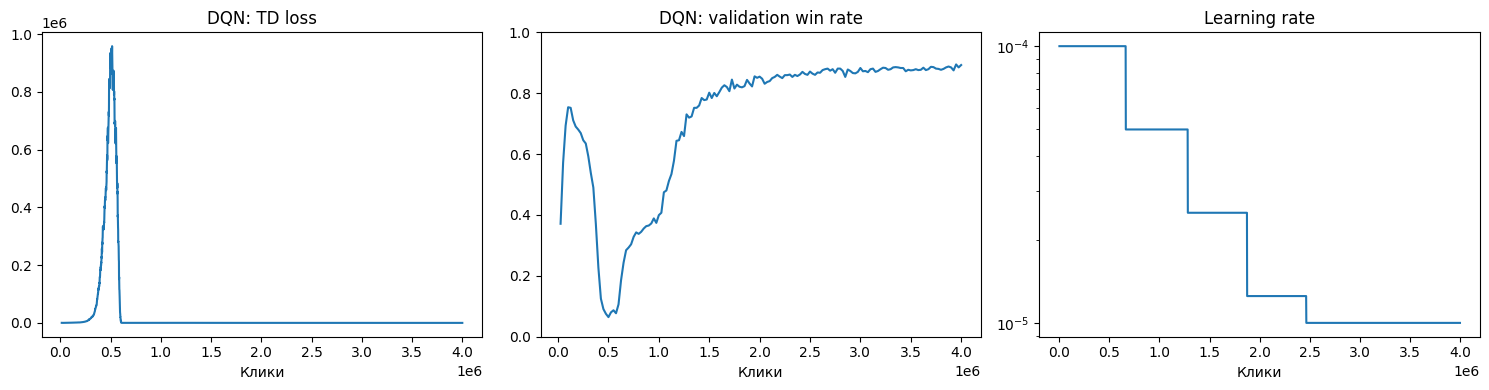

DQN: runs/minesweeper_dqn_paper/best.pt, 3,950,121 кликов
SL: checkpoints/latest.pt, 2,000,000 кликов
250/2000 полей; прошло 10 с, осталось ≈68 с
500/2000 полей; прошло 16 с, осталось ≈47 с
750/2000 полей; прошло 24 с, осталось ≈39 с
1000/2000 полей; прошло 29 с, осталось ≈29 с
1250/2000 полей; прошло 35 с, осталось ≈21 с
1500/2000 полей; прошло 41 с, осталось ≈14 с
1750/2000 полей; прошло 48 с, осталось ≈7 с
2000/2000 полей; прошло 55 с, осталось ≈0 с
Метод  Победы      Доля     95% интервал       Ходы
DQN    1768/2000  88.40% [86.92%, 89.73%]   6.97
SL     1851/2000  92.55% [91.32%, 93.62%]   8.08
SP     1719/2000  85.95% [84.36%, 87.40%]   8.03
CSP    1912/2000  95.60% [94.61%, 96.41%]   8.97
DQN − SL: -4.15 п.п.; 95% парный интервал [-5.89; -2.41] п.п.
DQN − SP: +2.45 п.п.; 95% парный интервал [+0.48; +4.42] п.п.
DQN − CSP: -7.20 п.п.; 95% парный интервал [-8.80; -5.60] п.п.
DQN-отчёт: /Users/a1234/Documents/ML/Minesweeper/results/dqn_best_3950121_89c44675_mps


In [45]:
plot_dqn_history(DQN_RUN_DIR)
DQN_EVAL_CHECKPOINT = DQN_RUN_DIR / 'best.pt'
if not DQN_EVAL_CHECKPOINT.exists():
    DQN_EVAL_CHECKPOINT = DQN_RUN_DIR / 'latest.pt'
DQN_SL_CHECKPOINT = Path('checkpoints/latest.pt')

if DQN_EVAL_CHECKPOINT.exists():
    dqn_model, dqn_eval_cfg, dqn_metadata = load_dqn_model(DQN_EVAL_CHECKPOINT, DEVICE)
    _, dqn_test_layouts, _ = make_dqn_holdouts(dqn_eval_cfg)
    print(f"DQN: {DQN_EVAL_CHECKPOINT}, {dqn_metadata['env_steps']:,} кликов")
    sl_model, sl_metadata = None, None
    if DQN_SL_CHECKPOINT.exists():
        sl_checkpoint = torch.load(DQN_SL_CHECKPOINT, map_location='cpu', weights_only=True)
        sl_cfg = Config(**sl_checkpoint['config'])
        _, sl_layouts = make_holdout_layouts(sl_cfg)
        if ((sl_cfg.rows, sl_cfg.cols, sl_cfg.n_mines, sl_cfg.first_action) !=
                (dqn_eval_cfg.rows, dqn_eval_cfg.cols, dqn_eval_cfg.n_mines, dqn_eval_cfg.first_action)
                or sl_layouts != dqn_test_layouts):
            raise ValueError('SL и DQN должны сравниваться на одинаковом тестовом протоколе')
        sl_model = Network(sl_cfg.rows, sl_cfg.cols).to(DEVICE)
        sl_model.load_state_dict(sl_checkpoint['model'])
        sl_model.eval()
        sl_metadata = {'checkpoint': str(DQN_SL_CHECKPOINT),
                       'env_steps': int(sl_checkpoint['env_steps']),
                       'sha256': hashlib.sha256(DQN_SL_CHECKPOINT.read_bytes()).hexdigest()}
        print(f"SL: {DQN_SL_CHECKPOINT}, {sl_metadata['env_steps']:,} кликов")
    dqn_comparison = compare_dqn_policies(dqn_model, dqn_test_layouts, dqn_eval_cfg,
                                           DEVICE, sl_model=sl_model)
    dqn_report_dir = Path('results') / (
        f"dqn_{DQN_EVAL_CHECKPOINT.stem}_{dqn_metadata['env_steps']}_"
        f"{dqn_metadata['checkpoint_sha256'][:8]}_{DEVICE.type}")
    save_dqn_report(dqn_comparison, dqn_metadata, dqn_report_dir, DEVICE, sl_metadata)
else:
    print('Обученного DQN-checkpoint пока нет; сравнение пропущено.')
